### First figures  

* histogram plot showing the number of documents over the years
* histogram plot showing which are most common in the prediction set
* a map of the locations of the infrastrucutre damages 





In [100]:
import os
import sys
from pathlib import Path
import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sys.path.append('../')
from src.settings import settings as s
import src.document_cleaning as dc
import src.translation_model as tm
import src.utils as u
import src.datahandler as dh
import src.postprocess as pp
import src.visualization as v

# login to HF
# NOTE raises exception when env.variable does not exist (compared to os.envrion.get and its shortcut os.getenv)
os.getenv("HUGGINGFACE_TOKEN")

#  automatic linebreaks and multi-line cells.
pd.set_option("display.colheader_justify", "left")
pd.set_option('display.max_colwidth', 5000)


# set working dir
print("Running on local machine")
os.chdir("/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/")

# HF directory
HF_HOME_DIR: str = "/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/notebooks/huggingface_mirror/hub"
HF_TOKEN_PATH: str = "/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/notebooks/huggingface_mirror/token"

# step = "step2"
step = "judge"


Running on local machine


In [119]:
## data to plot


#  Define data dir where tags.csv and domain-expertise derived tag lists are found 
# VALID_DATA_FILENAME = s.VALID_DATA_FILENAME
VALID_DATA_FILENAME = "table_ci_impacts_sm_casc_hpc.csv"
PATH_VALID_DATA = s.PATH_VALID_DATA

s.LLM_DATA_FILENAME = f"df_responses_{step}_ner_geollm.csv"
LLM_DATA_FILEPATH = Path(s.PATH_LLM_DATA / s.LLM_DATA_FILENAME)

df_valid_org = pd.read_csv(
    PATH_VALID_DATA / VALID_DATA_FILENAME,
    # usecols=["publication_id", "ci1_type", "ci1_damage", "ci1_location", "sentence_reference"],
)
print(len(df_valid_org))
## pre-process: 
# remove undone entries
df_valid_org = df_valid_org[~df_valid_org.astype(str).apply(lambda x: x.str.contains("xx")).any(axis=1)]
# remove further location info (e.g. that entry is a town, Landkreis, Bavaria etc.)
# df_valid_org["ci1_location"] = df_valid_org["ci1_location"].replace(r"\s*\(.*\)", "", regex=True).str.strip()
df_valid_org = df_valid_org.dropna(subset=["publication_id"], how="all") # drop rows where citation info is missing
print(len(df_valid_org))
print(df_valid_org.publication_id.unique())

df_valid = df_valid_org

print(f"Collecting LLM responses from {step}")
# ## prediction data
# df_pred = pd.read_csv(
#     LLM_DATA_FILEPATH,
#    # usecols=["citation_id", "chunk_id", "infrastructure_type", "damage", "location", "chunk_text"]
# )
df_pred = pd.DataFrame()
# for i, file in enumerate(glob.glob(os.path.join(s.PATH_DATA, "llm_outputs/responses_single_docs", f'*{step}*.csv'))):
for i, file in enumerate(glob.glob(os.path.join("../interim_results_debug_24oct", f'llm_*chain_{step}*.csv'))):
    print(i, file)
    try:
        df_pred = pd.concat([df_pred, pd.read_csv(file)], ignore_index=True)
    except:
        print("Could not load:", file)

# df_pred = pd.read_csv("/home/a-buch/Documents/TUB_DWN/_PROJECTS/interim_results_debug/llm_geollm_chain_step1_Koks 2022.csv")


397
342
<ArrowStringArray>
[                            'ABC 2024',
 'not clear if this affected trnasport',
                         'Artemis 2015',
                           'Brown 2010',
                   'Containerlift 2024',
                          'Deidda 2025',
                             'EFE 2024',
                        'Euronews 2024',
        'European Investment Bank 2025',
                         'Ferlita 2023',
               'Gilbody Dickerson 2024',
                     'Karakatsani 2023',
                            'Kaur 2025',
                          'Kettle 2020',
                            'Nour 2011',
                          'Chamra 2006',
                        'Mitsakis 2014',
                       'Pescaroli 2017',
                          'Hladny 2004',
                            'Fink 2009',
                          'Keller 2014',
                          'Khazai 2013',
                            'Zeit 2021',
                            'K

In [120]:
df_pred.info()


<class 'pandas.DataFrame'>
RangeIndex: 245 entries, 0 to 244
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   is_infrastructure_case          245 non-null    bool  
 1   infrastructure_type             245 non-null    str   
 2   infrastructure_amount           36 non-null     object
 3   location                        202 non-null    str   
 4   damage                          208 non-null    str   
 5   economic_impact_type            37 non-null     object
 6   economic_impact_origin          35 non-null     object
 7   economic_impact_amount          14 non-null     object
 8   economic_impact_unit            17 non-null     object
 9   societal_impact_origin          47 non-null     object
 10  societal_impact_type            38 non-null     object
 11  societal_impact_amount          28 non-null     object
 12  societal_impact_unit            26 non-null     object
 13  s

In [121]:
ci_patterns = pd.read_json("./ner_patterns.jsonl/patterns", lines=True)


## group Ci types into CI groups and CI sectors
# if not "infrastructure_group" in df_pred.columns or df_pred["infrastructure_group"].isna().any():
df_pred[["infrastructure_group", "infrastructure_sector", "secondary_infrastructure_group", "secondary_infrastructure_sector"]] = None
df_pred = pp.group_ci_types(df_pred, "infrastructure_type", "infrastructure_group", ci_patterns)
df_pred = pp.group_ci_types(df_pred, "infrastructure_type", "infrastructure_sector", ci_patterns, grouping_scheme="sector")
df_pred = pp.group_ci_types(df_pred, "secondary_infrastructure_asset", "secondary_infrastructure_group", ci_patterns)
df_pred = pp.group_ci_types(df_pred, "secondary_infrastructure_asset", "secondary_infrastructure_sector", ci_patterns,  grouping_scheme="sector")

# if not "ci1_group" in df_valid.columns or df_valid["ci1_group"].isna().any():
df_valid[["ci1_group", "infrastructure_sector", "secondary_infrastructure_group", "secondary_infrastructure_sector"]] = None
df_valid = pp.group_ci_types(df_valid, "ci1_type", "ci1_group", ci_patterns)
df_valid = pp.group_ci_types(df_valid, "ci1_group", "infrastructure_sector", ci_patterns,  grouping_scheme="sector")
df_valid = pp.group_ci_types(df_valid, "secondary_infrastructure_asset", "secondary_infrastructure_group", ci_patterns)
df_valid = pp.group_ci_types(df_valid, "secondary_infrastructure_group", "secondary_infrastructure_sector", ci_patterns,  grouping_scheme="sector")


# see which could not be grouped
# df_plot[df_plot.secondary_infrastructure_group.isna() & ~ df_plot.secondary_infrastructure_asset.isna()]


# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # # print(df_plot["secondary_infrastructure_group"].unique())
# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_sector"].str.split(" - ").str[0]




### figure labels

In [82]:
# ## nice labeling for CI

# cigroup_labels = {
#     "airports" : "Transportation - Aviation",
#     "aviation" : "Transportation - Aviation",
#     "roads" : "Transportation - Road network",
#     "road_others" : "Transportation - Road network",
#     "bridges" : "Transportation - Bridges",
#     "motorways" : "Transportation - Highways / Motorways",
#     "rail" : "Transportation - Rail network",
#     "railway_station":  "Transportation - Rail network",
#     "rail_service":  "Transportation - Rail service",
#     "metro" :  "Transportation - Rail network",
#     "ports" : "Transportation - Shipping traffic",
#     "waterways_ships" : "Transportation - Shipping traffic",
#     "maritime" : "Transportation - Shipping traffic",
#     "inland_waterways" : "Transportation - Inland shipping",
#     "transport_others": "Transportation - Transportation (not further specified)",
#     "transport_service": "Transportation - Transportation (not further specified)",
#     "transport_general": "Transportation - Transportation (not further specified)",

#     "water_distribution" : "Water - Water network",
#     "water_others" : "Water - Water network",
#     "water_supply" : "Water - Water supply",
#     "waterprotection" : "Structural protection measures - Flood protection",

#     "electricity_distribution" :  "Energy - Electricity network",
#     "electricity_others" : "Energy - Electricity network",
#     "power_plants" : "Energy - Electricity network",
#     "nonrenewable_others" : "Energy - Non-renewable energy",
#     "renewable" : "Energy - Renewable energy",
#     "petrol_gas_stations_consumers" :  "Energy - Electricity supply",
#     "electricity_supply" : "Energy - Electricity supply",

#     "gas_distribution" : "Energy - Gas network",
#     "gas_storage" : "Energy - Gas network",
#     "gas_supply" : "Energy - Gas supply",

#     "wastewater" : "Waste - Wastewater",
#     "waste_others" : "Waste - Waste (not further specified)",
#     "waste_treatment" : "Waste - Waste treatment",

#     "it_telecommunication" : "IT / communication - IT / communication (not further specified)", #Not specified",
#     "it_telecom_distribution" : "IT / communication - IT / communication (distribution)",
#     "it_telecom_supply" : "IT / communication - IT / communication (supply)", 

#     "industry_heavy": "Industry - Chemical or heavy industry",

#     "healthcare_others" : "Social - Healthcare (not further specified)", # Not specified",
#     "healthcare_general" : "Social - Healthcare (not further specified)", # Not specified",
#     "healthcare_hospitals_clinics" : "Social - Hospitals / clinics",
#     "healthcare_clinics" : "Social - Hospitals / clinics",
#     "education_kita" : "Social - Day care centres",
#     "education_school" : "Social - Schools",
#     "education_others" :  "Social - Education (not further specified)",
# }


### Donut plot -  most common CI in validation + prediction set


In [90]:

def figure_donuts(df_plot:pd.DataFrame, col_labels: str, col_sizes:str, col_groups: str, base_palettes:dict, startangle:int=170):


    # --- Seaborn style ---
    sns.set_theme(style="white", context="talk")


    groups = df_plot[col_groups]
    # labels = df_plot[col_labels]
    # sizes = df_plot[col_sizes]
    

    ## Sector colors
    unique_sectors = groups.unique()

    sector_palettes = {}

    for sector in unique_sectors:
        n = (groups == sector).sum()
        palette_name = base_palettes.get(sector, "Greys")

        # soft gradient (skip very light colors)
        palette = sns.color_palette(palette_name, n + 3)[2:]
        sector_palettes[sector] = palette

    # Assign colors
    colors = []
    counters = {s: 0 for s in unique_sectors}
    for s in groups:
        colors.append(sector_palettes[s][counters[s]])
        counters[s] += 1


    ## Sectors
    sizes_with_gaps = []
    colors_with_gaps = []
    meta = []  # 🔥 keeps mapping to original data
    labels_with_gaps = []


    ## Gap between sectors
    gap_fraction = 0.04
    gap_size = df_plot[col_sizes].sum() * gap_fraction

    for sector in unique_sectors:
        sector_df = df_plot[df_plot[col_groups] == sector]

        for j, (_, row) in enumerate(sector_df.iterrows()):
            sizes_with_gaps.append(row[col_sizes])
            colors_with_gaps.append(sector_palettes[sector][j])

            meta.append({
                "label": row[col_labels], #.split(" - ")[1],
                "size": row[col_sizes],
                "color": sector_palettes[sector][j],
                "is_gap": False
            })

        # ✅ equal gap (NOT proportional anymore)
        sizes_with_gaps.append(gap_size)
        colors_with_gaps.append((1, 1, 1, 1))

        meta.append({"is_gap": True})


    # Now rebuild colors in same order
    colors_with_gaps = []
    for sector in unique_sectors:
        sector_df = df_plot[df_plot[col_groups] == sector]
        for i in range(len(sector_df)):
            colors_with_gaps.append(sector_palettes[sector][i])
        colors_with_gaps.append((1, 1, 1, 1))  # gap color


    ####### INNER RING 

    # --- Build INNER ring (sector level, aligned with gaps) ---
    inner_sizes = []
    inner_colors = []

    for sector in unique_sectors:
        sector_df = df_plot[df_plot[col_groups] == sector]

        # total size of sector
        sector_total = sector_df[col_sizes].sum()

        # ONE slice for the sector
        inner_sizes.append(sector_total)

        # pick representative color (middle of palette)
        palette = sector_palettes[sector]
        inner_colors.append(palette[len(palette) // 2])

        # SAME gap as outer ring
        # gap_size = sector_total * gap_fraction
        inner_sizes.append(gap_size)
        inner_colors.append((1, 1, 1, 1))  # white gap
    ########

    # sizes_with_gap = list(df_plot["count"]) + [gap_size]
    # colors_with_gap = colors + [(1, 1, 1, 0)]  # fully transparent



    #####                     PLOT                      ####  
    
    # Startangle of donut
    startangle = startangle # 170 #- (gap_size / sum(sizes_with_gaps)) * 180
    
    
    #####                     PLOT  OUTER DONUT                      ####  

    fig, ax = plt.subplots(figsize=(20, 25))

    ## Actual donut chart
    wedges, _ = ax.pie(
        sizes_with_gaps,
        colors=colors_with_gaps,
        startangle=startangle,
        wedgeprops=dict(width=0.12, edgecolor="white", linewidth=2)
    )

    # # --- Leader lines at END of each segment ---
    # real_wedges = wedges[:-1]
    real_indices = [i for i, lbl in enumerate(labels_with_gaps) if lbl is not None]
    real_wedges = [wedges[i] for i in real_indices]


    # --- Collect positions first ---

    label_data = []

    for i, wedge in enumerate(wedges):
        if meta[i]["is_gap"]:
            continue  # 🔥 skip gaps safely

        angle = wedge.theta2 - 0.3
        rad = np.deg2rad(angle)

        x, y = np.cos(rad), np.sin(rad)

        start = (x * 1.0, y * 1.0)
        mid = (x * 1.25, y * 1.25)

        end_x = 1.35 if x > 0 else -1.35
        text_x = end_x + 0.08 if x > 0 else end_x - 0.08

        label_data.append({
            "i": i,
            "start": start,
            "mid": mid,
            "end_x": end_x,
            "text_x": text_x,
            "end_y": mid[1],
            "side": "right" if x > 0 else "left"
        })

    # Split left/right
    left = [d for d in label_data if d["side"] == "left"]
    right = [d for d in label_data if d["side"] == "right"]

    import src.visualization as v

    left = v.adjust_positions(left)
    right = v.adjust_positions(right)

    # Merge back
    label_data = left + right

    # # --- Draw lines + labels ---
    for d in label_data:
        i = d["i"]
        m = meta[i]

        align = "left" if d["side"] == "right" else "right"

        ax.plot([d["start"][0], d["mid"][0]],
                [d["start"][1], d["mid"][1]],
                color=m["color"], lw=4)

        ax.plot([d["mid"][0], d["end_x"]],
                [d["mid"][1], d["end_y"]],
                color=m["color"], lw=4)

        ax.text(
            d["text_x"],
            d["end_y"],
            f"{m['label']} [n={m['size']}]",
            ha=align,
            va="center",
            fontsize=25
        )

        # Anchor point on donut (slightly outside ring)
        anchor_x = d["start"][0] * 1.01
        anchor_y = d["start"][1] * 1.01
        ax.scatter(anchor_x, anchor_y, color=m["color"], s=35, zorder=30)

        
    ####### PLOT INNER

    # --- INNER ring (sectors) ---
    wedges_inner, _ = ax.pie(
        inner_sizes,
        radius=0.85,   # smaller than outer, 
        colors=inner_colors,
        startangle=startangle,  # MUST match outer ring
        wedgeprops=dict(width=0.30, edgecolor="white", linewidth=0) # inner ring thickness etc
    )

    for i, wedge in enumerate(wedges_inner):
        # skip gap slices (every second entry)
        if i % 2 == 1:
            continue

        angle = (wedge.theta1 + wedge.theta2) / 2
        rad = np.deg2rad(angle)

        x, y = np.cos(rad), np.sin(rad)

    plt.show()


In [107]:
df_pred.citation_id.unique()

<ArrowStringArray>
[                     'AFP 2022', 'European Investment Bank 2025',
                     'Fink 2004',                   'Wilson 2024',
                    'Brown 2010',            'Containerlift 2024',
                'Wildhagen 2013',                'Skoulding 2023',
              'Karakatsani 2023',                      'EFE 2024',
                  'Ferlita 2023',                     'Koks 2022',
             'Lloyd's List 2024',                   'Khazai 2013',
                      'ABC 2024',                 'Euronews 2024',
                'Rozendaal 2021']
Length: 17, dtype: str

In [93]:
# df_pred.infrastructure_group.unique()
df_pred.infrastructure_sector.unique()

<ArrowStringArray>
[                'Transportation',                         'Health',
                         'Energy',                              nan,
 'Structural Protection Measures',                          'Water',
             'IT / Communication',                          'Waste',
                      'Education']
Length: 9, dtype: str

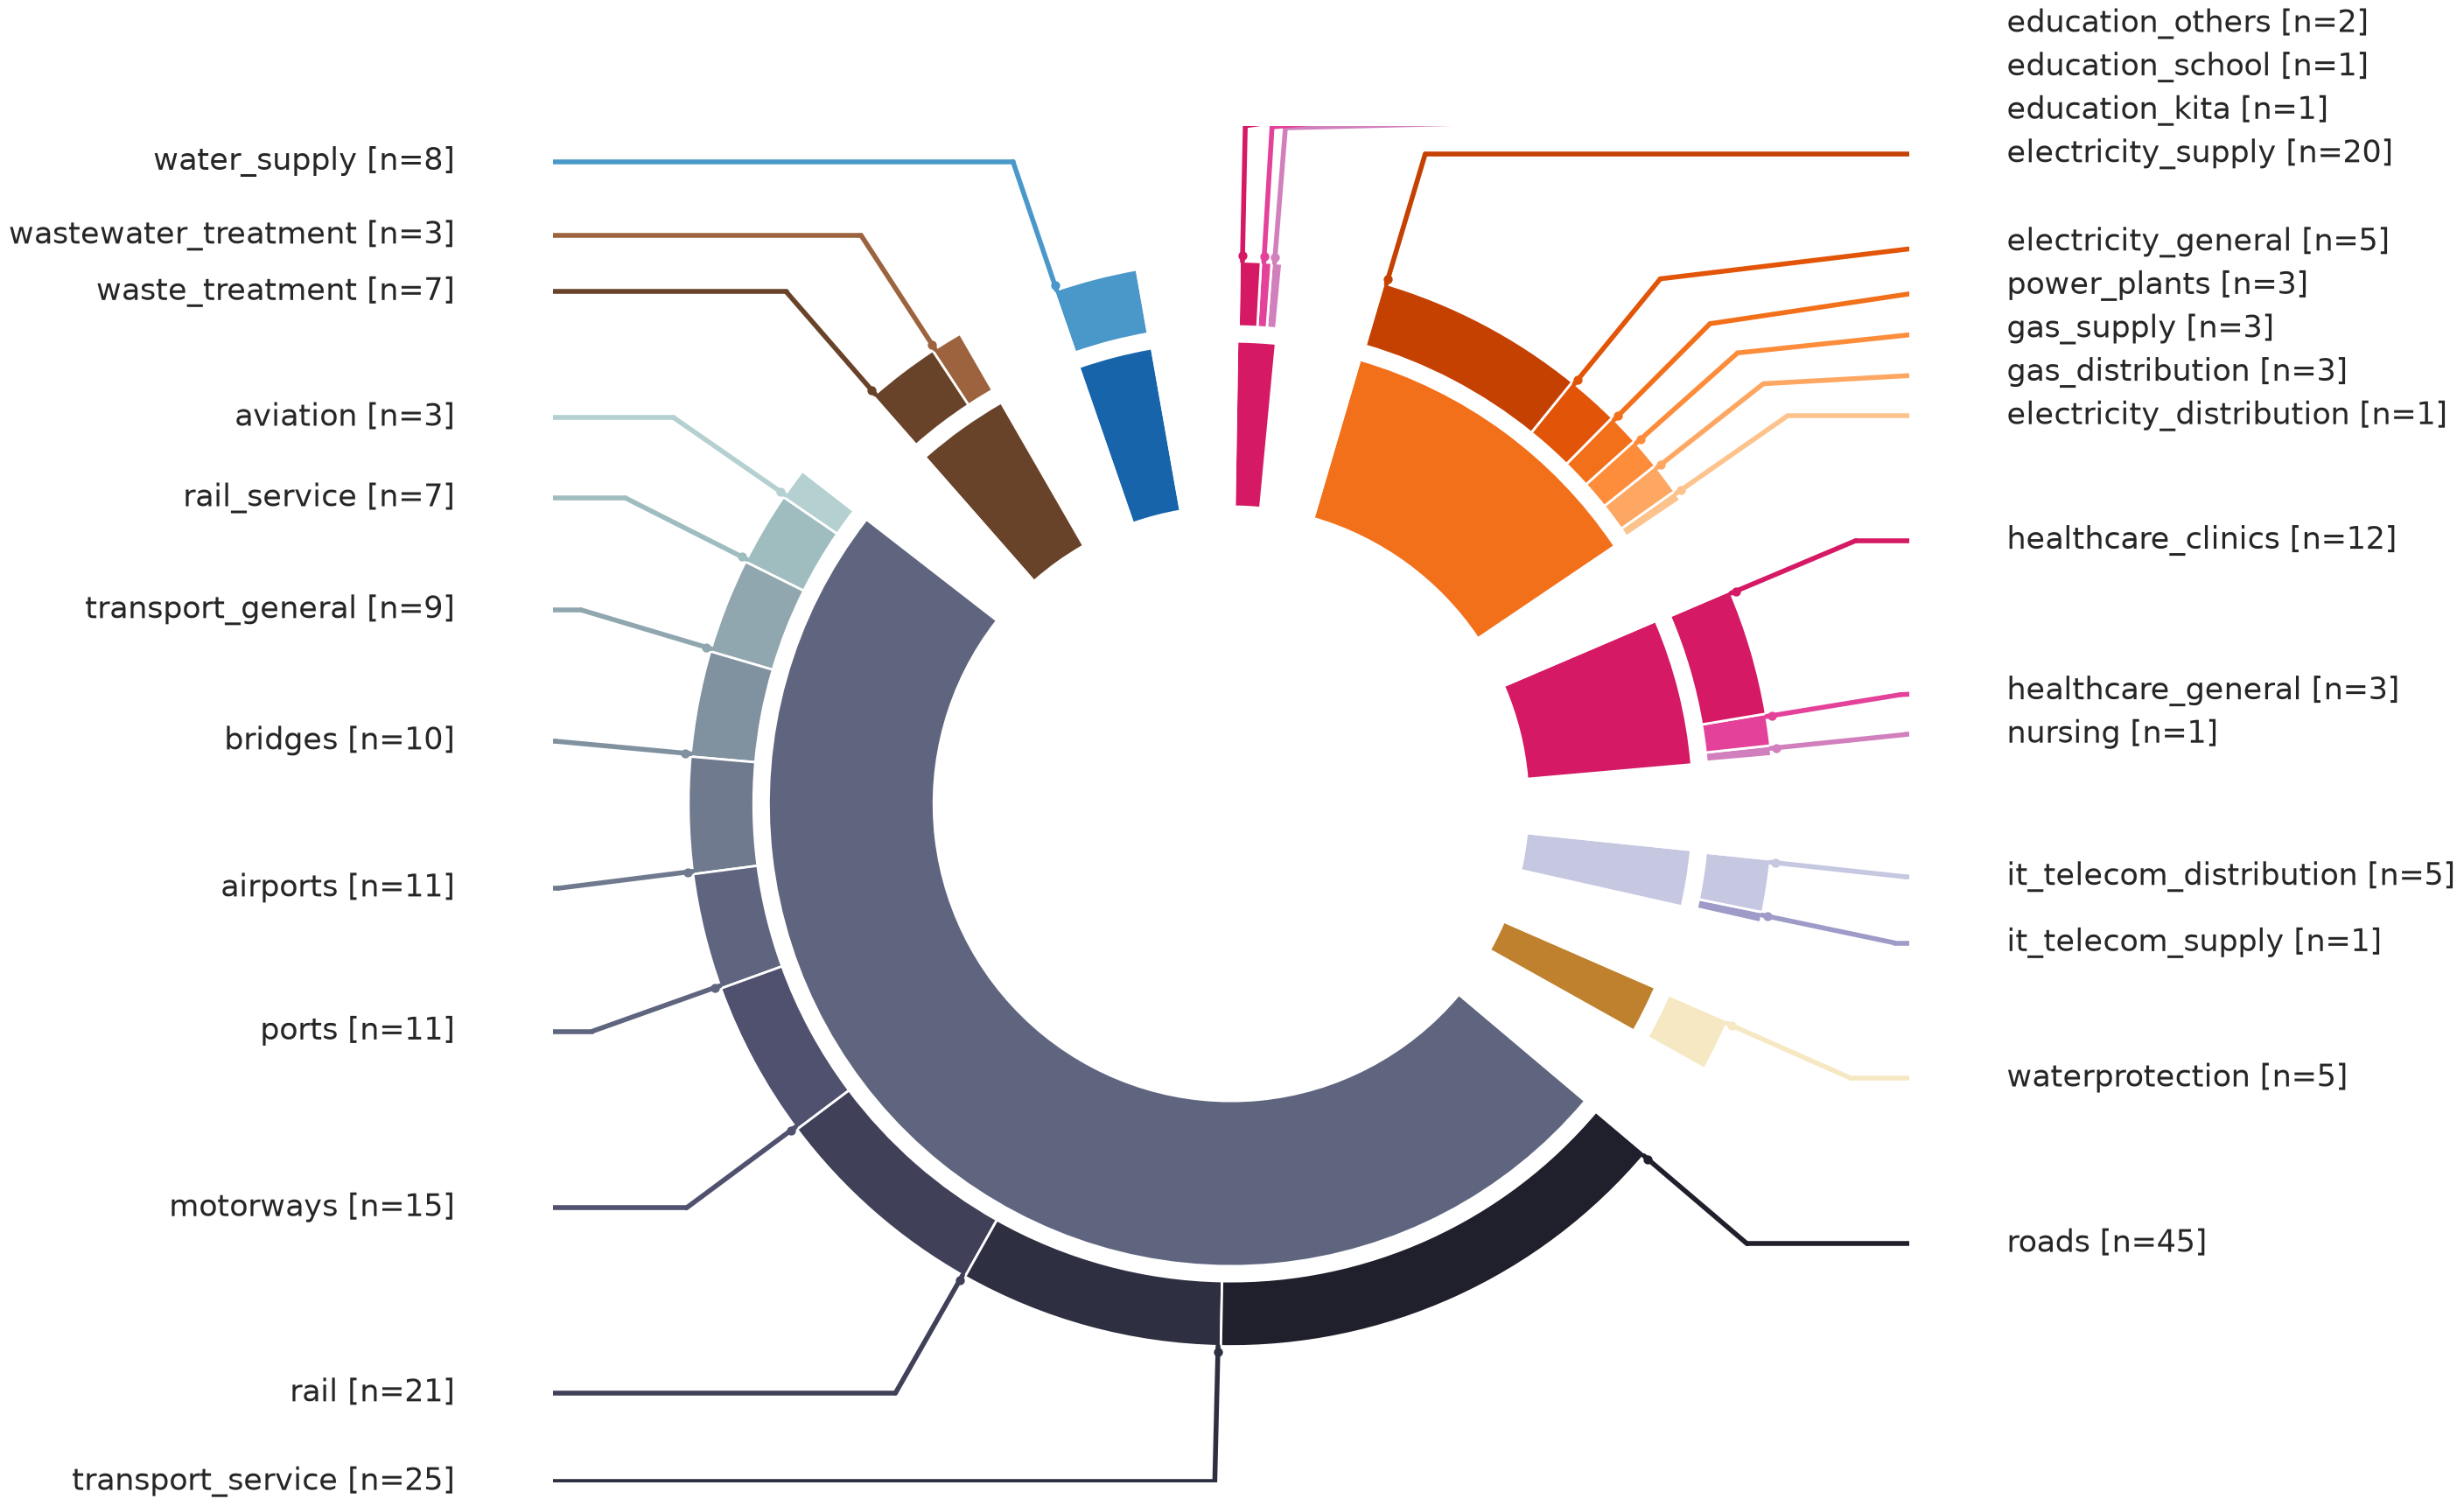

0

In [94]:

base_palettes = {
    "Transportation": "bone_r", #"Greys",
    "Energy": "Oranges",
    "Water": "Blues",
    "Structural Protection Measures": "BrBG_r", # "cividis_d", # "Greens_d",
    "Waste": "copper_r",
    "Health": "PuRd",
    "Education": "PuRd",
    "Other": "Greys_r",
    "IT / Communication": "Purples_r",
    "gap": "Black"  # for the gap piece
}


# ## VALID
# df_plot = df_valid.copy(deep=True)

# ## Prep - create sector and subsector ("group") columns with nice labels 
# print(df_plot["ci1_group"].unique())
# df_plot["ci1_group"] = df_plot["ci1_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# df_plot["ci1_sector"] = df_plot["ci1_group"].str.split(" - ").str[0]

# #  Aggregate and sort data ---
# df_plot = (
#     df_plot.groupby(["ci1_sector", "ci1_group"]).size().reset_index(name="count")
# )
# # Sort by group then value (important for visual grouping)
# df_plot = df_plot.sort_values(
#     ["ci1_sector", "count"],
#     ascending=[False, True]
# )
# figure_donuts(df_plot=df_plot, col_labels= "ci1_group", col_sizes="count", col_groups="ci1_sector", base_palettes=base_palettes, startangle=201)



# ## PRED

df_plot = df_pred.copy(deep=True)

# ## Prep - create sector and subsector ("group") columns with nice labels 
# print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group"].str.split(" - ").str[0]


#  Aggregate and sort data ---
df_plot = (
    df_plot.groupby(["infrastructure_sector", "infrastructure_group"]).size().reset_index(name="count")
)
# Sort by group then value (important for visual grouping)
df_plot = df_plot.sort_values(
    ["infrastructure_sector", "count"],
    ascending=[False, True]
)
figure_donuts(df_plot=df_plot, col_labels= "infrastructure_group", col_sizes="count", col_groups="infrastructure_sector", base_palettes=base_palettes, startangle=100)


0

In [89]:
df_plot.columns

Index(['infrastructure_sector', 'infrastructure_group', 'count'], dtype='str')

In [52]:
df_plot.columns

Index(['infrastructure_sector', 'infrastructure_group', 'count'], dtype='str')

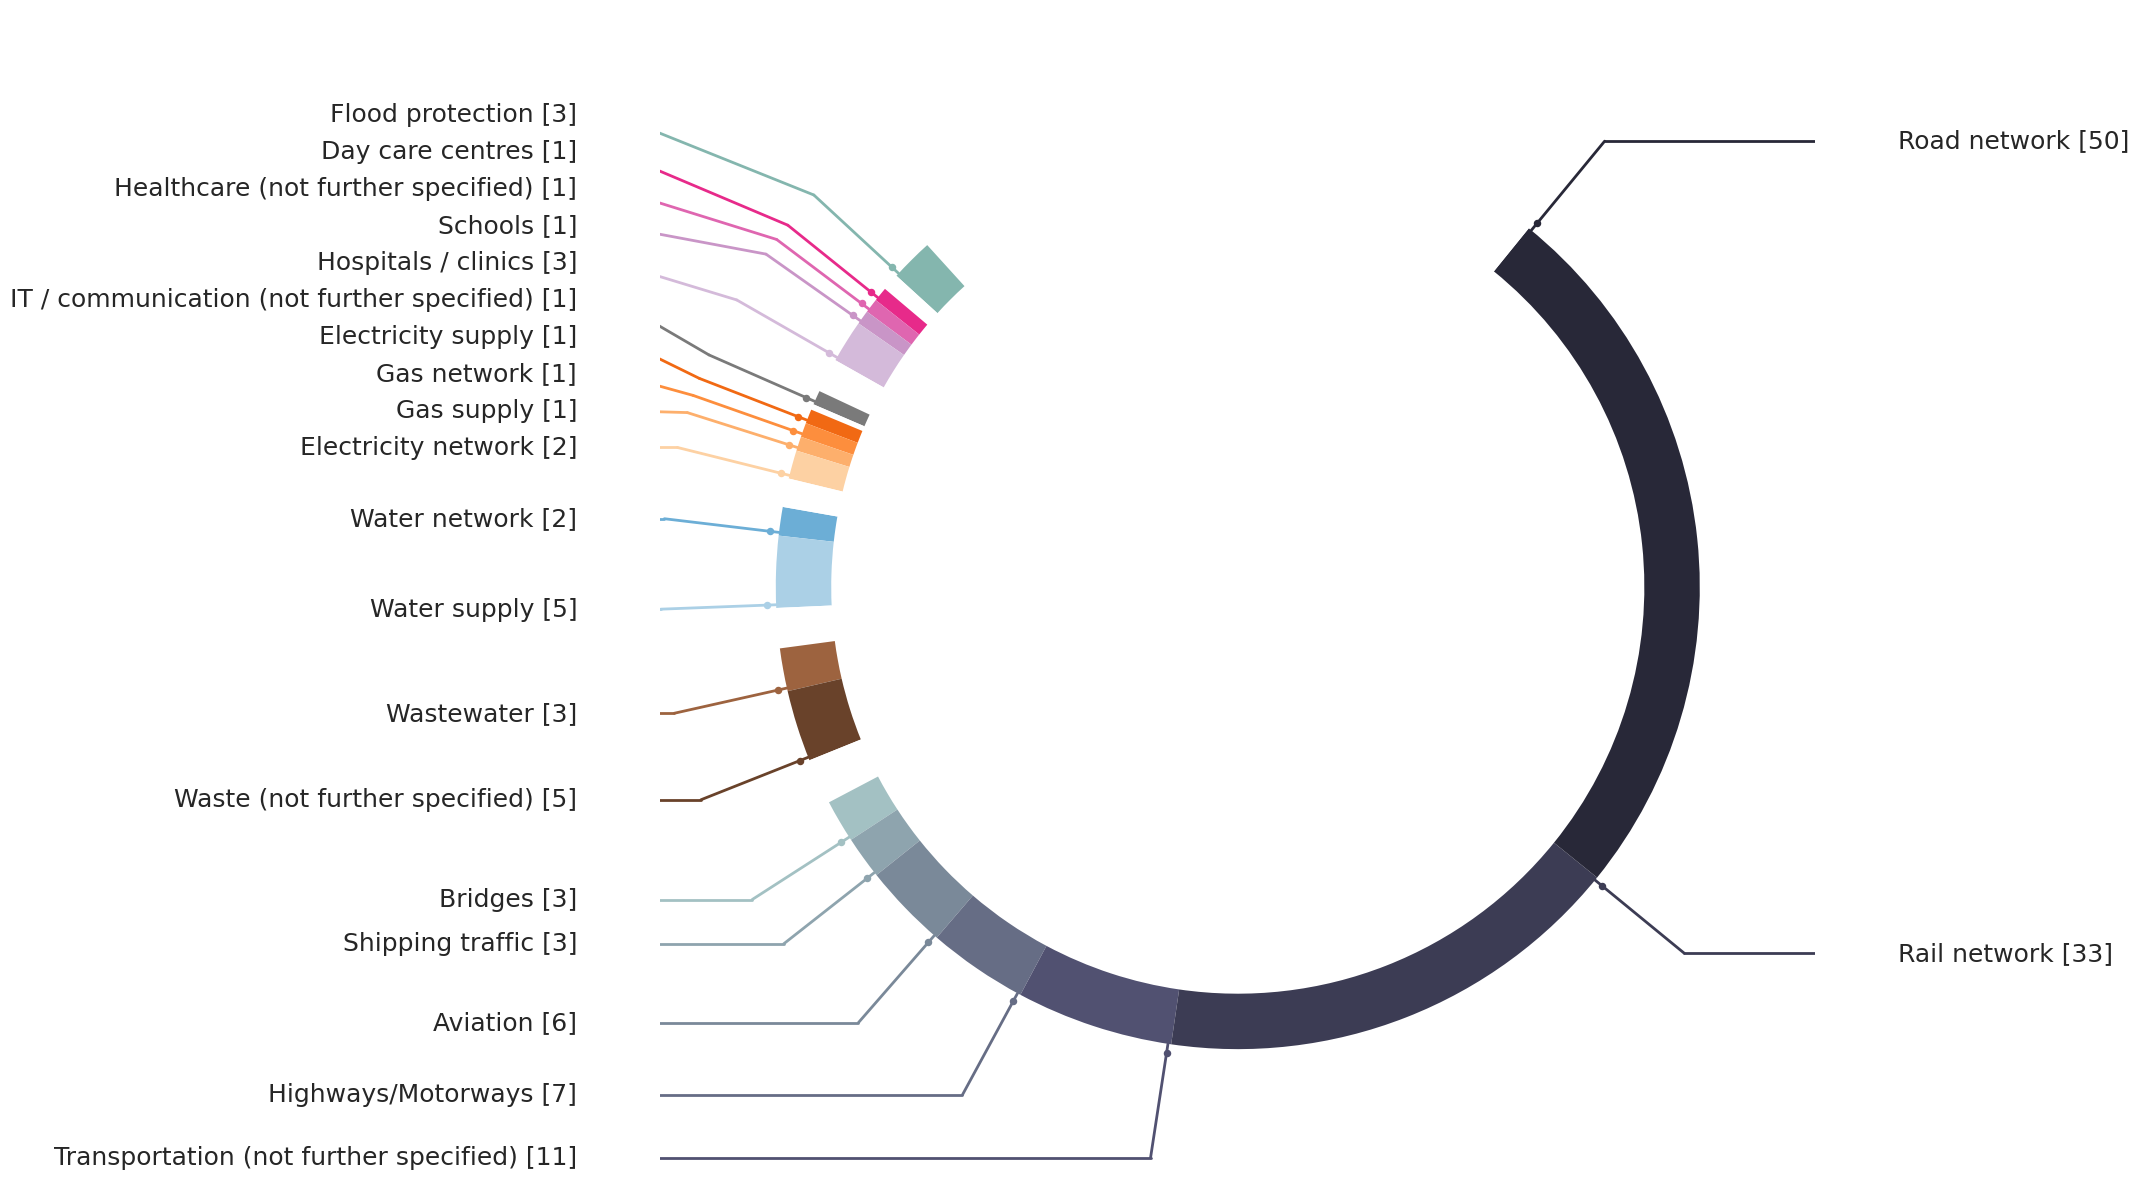

In [ ]:
# # REST - DONUT - only one ring

# import matplotlib.pyplot as plt
# import seaborn as sns


# # --- Seaborn style ---
# sns.set_theme(style="white", context="talk")

# ## Prep - create sector and subsector ("group") columns with nice labels 
# df_plot = df_pred.copy(deep=True)
# # nice lables for CI group (ie Ci subsector) and sector
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group"].str.split(" - ").str[0]


# # # --- Aggregate data correctly ---
# df_plot = (
#     df_plot.groupby(["infrastructure_sector", "infrastructure_group"]).size().reset_index(name="count")
# )


# # Sort by group then value (important for visual grouping)
# df_plot = df_plot.sort_values(
#     ["infrastructure_sector", "count"],
#     ascending=[False, True]
# )



# labels = df_plot["infrastructure_group"]
# sizes = df_plot["count"]
# groups = df_plot["infrastructure_sector"]
# unique_sectors = groups.unique()

# base_palettes = {
#     "Transportation": "bone_r", #"Greys",
#     "Energy": "Oranges_r",
#     "Water": "Blues_r",
#     "Structural Protection Measures": "BrBG_d", # "cividis_d", # "Greens_d",
#     "Waste": "copper_r",
#     "Education": "PuRd_r",
#     "Health": "PuRd_r",
#     "Other": "Greys_r",
#     "IT / Communication": "Purples_r",
#     "gap": "White"  # for the gap piece
# }


# ## Sector colors
# sector_palettes = {}

# for sector in unique_sectors:
#     n = (groups == sector).sum()
#     palette_name = base_palettes.get(sector, "Greys")

#     # soft gradient (skip very light colors)
#     palette = sns.color_palette(palette_name, n + 3)[2:]
#     sector_palettes[sector] = palette

# # Assign colors
# colors = []
# counters = {s: 0 for s in unique_sectors}
# for s in groups:
#     colors.append(sector_palettes[s][counters[s]])
#     counters[s] += 1


# ## Sectors
# sizes_with_gaps = []
# colors_with_gaps = []
# meta = []  # 🔥 keeps mapping to original data

# gap_fraction = 0.4

# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]

#     for j, (_, row) in enumerate(sector_df.iterrows()):
#         sizes_with_gaps.append(row["count"])
#         colors_with_gaps.append(sector_palettes[sector][j])

#         meta.append({
#             "label": row["infrastructure_group"].split(" - ")[1],
#             "size": row["count"],
#             "color": sector_palettes[sector][j],
#             "is_gap": False
#         })

#     # add sector gap
#     gap_size = sector_df["count"].sum() * gap_fraction
#     sizes_with_gaps.append(gap_size)
#     colors_with_gaps.append((1, 1, 1, 1))

#     meta.append({
#         "is_gap": True
#     })

# # Now rebuild colors in same order
# colors_with_gaps = []
# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]
#     for i in range(len(sector_df)):
#         colors_with_gaps.append(sector_palettes[sector][i])
#     colors_with_gaps.append((1, 1, 1, 1))  # gap color


# ## Gap piece
# # gap_size = 50 # df_plot["count"].sum() * 0.2  # controls how open it is (10–25% works well)
# gap_size = df_plot["count"].sum() * 0.3  # controls how open it is (10–25% works well)

# sizes_with_gap = list(df_plot["count"]) + [gap_size]
# colors_with_gap = colors + [(1, 1, 1, 0)]  # fully transparent


# ##### PLOT 

# fig, ax = plt.subplots(figsize=(15, 15))

# ## Actual donut chart
# wedges, _ = ax.pie(
#     sizes_with_gaps,
#     colors=colors_with_gaps,
#     startangle=170,
#     wedgeprops=dict(width=0.12, edgecolor="white", linewidth=0)
# )

# # # --- Leader lines at END of each segment ---
# # real_wedges = wedges[:-1]
# real_indices = [i for i, lbl in enumerate(labels_with_gaps) if lbl is not None]
# real_wedges = [wedges[i] for i in real_indices]


# # --- Collect positions first ---

# label_data = []

# for i, wedge in enumerate(wedges):
#     if meta[i]["is_gap"]:
#         continue  # 🔥 skip gaps safely

#     angle = wedge.theta2 - 0.4
#     rad = np.deg2rad(angle)

#     x, y = np.cos(rad), np.sin(rad)

#     start = (x * 1.0, y * 1.0)
#     mid = (x * 1.25, y * 1.25)

#     end_x = 1.35 if x > 0 else -1.35
#     text_x = end_x + 0.08 if x > 0 else end_x - 0.08

#     label_data.append({
#         "i": i,
#         "start": start,
#         "mid": mid,
#         "end_x": end_x,
#         "text_x": text_x,
#         "end_y": mid[1],
#         "side": "right" if x > 0 else "left"
#     })

# # Split left/right
# left = [d for d in label_data if d["side"] == "left"]
# right = [d for d in label_data if d["side"] == "right"]

# import src.visualization as v

# left = v.adjust_positions(left)
# right = v.adjust_positions(right)

# # Merge back
# label_data = left + right

# # # --- Draw lines + labels ---
# for d in label_data:
#     i = d["i"]
#     m = meta[i]

#     align = "left" if d["side"] == "right" else "right"

#     ax.plot([d["start"][0], d["mid"][0]],
#             [d["start"][1], d["mid"][1]],
#             color=m["color"], lw=2)

#     ax.plot([d["mid"][0], d["end_x"]],
#             [d["mid"][1], d["end_y"]],
#             color=m["color"], lw=2)

#     ax.text(
#         d["text_x"],
#         d["end_y"],
#         f"{m['label']} [{m['size']}]",
#         ha=align,
#         va="center",
#         fontsize=18
#     )

#     # Anchor point on donut (slightly outside ring)
#     anchor_x = d["start"][0] * 1.02
#     anchor_y = d["start"][1] * 1.02
#     ax.scatter(anchor_x, anchor_y, color=m["color"], s=15, zorder=3)
#     # df_plot = (
#     #     df_plot
#     #     .groupby(["infrastructure_sector", "infrastructure_group"])
#     #     .size()
#     #     .reset_index(name="count")
#     # )
    



'Water supply'

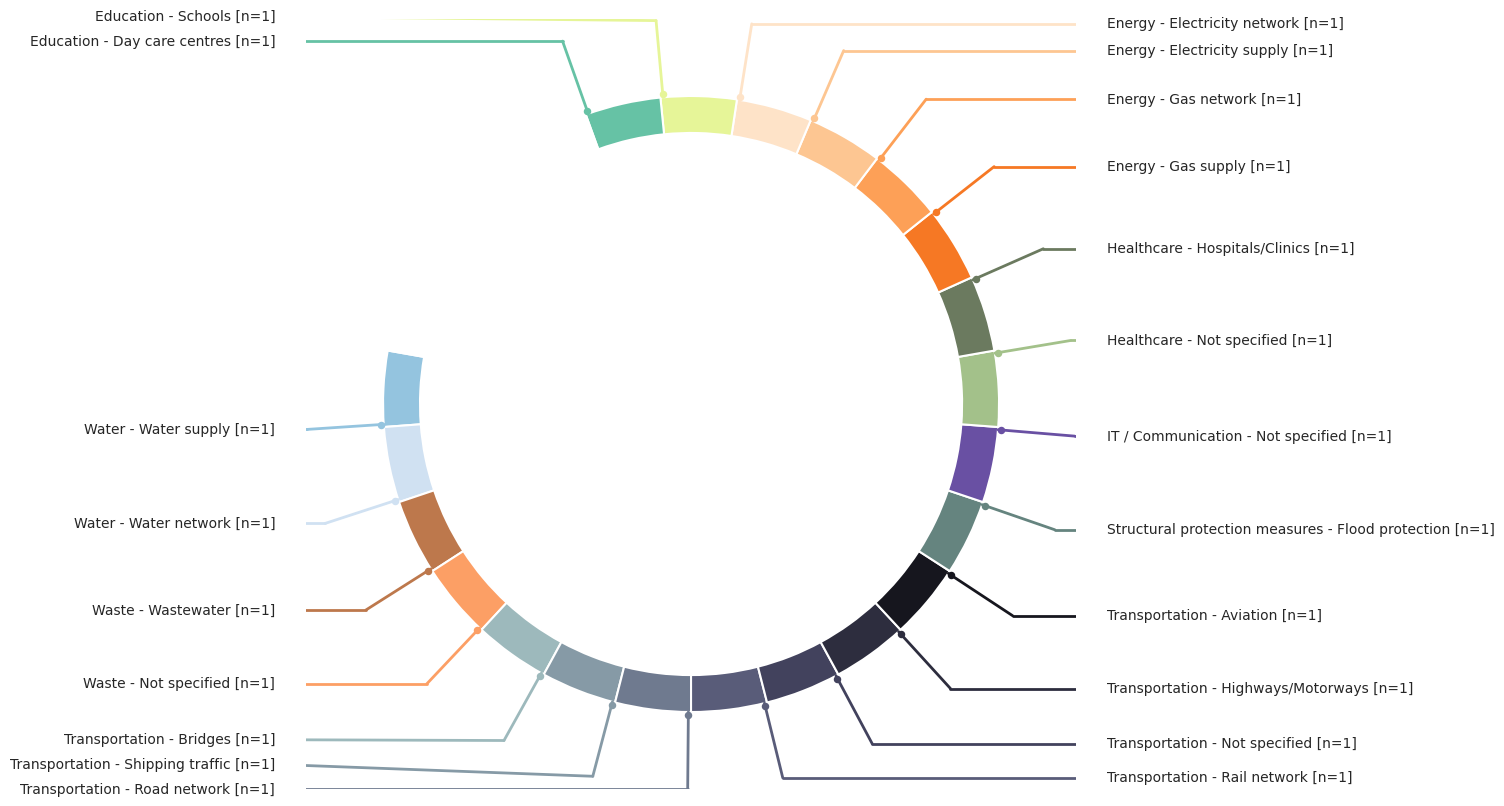

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns


# # --- Seaborn style ---
# sns.set_theme(style="white", context="talk")


# # # --- Aggregate data correctly ---
# df_plot = (
#     df_plot.groupby(["infrastructure_sector", "infrastructure_group"]).size().reset_index(name="count")
# )#.sort_values(["infrastructure_sector", "infrastructure_group"], ascending=True)


# # Sort by group then value (important for visual grouping)
# df_plot = df_plot.sort_values(
#     ["infrastructure_sector"],
#     # ["infrastructure_sector", "count"],
#     ascending=[False]
#     # ascending=[False, False]
# )
# # df_pred_plot = df_pred.groupby(["infrastructure_sector"])["infrastructure_group"].count().reset_index(name="infrastructure_group").sort_values(["infrastructure_group"], ascending=True)



# labels = df_plot["infrastructure_group"]
# sizes = df_plot["count"]
# groups = df_plot["infrastructure_sector"]
# unique_sectors = groups.unique()

# base_palettes = {
#     "Transportation": "bone_r", #"Greys",
#     "Energy": "Oranges_r",
#     "Water": "Blues_r",
#     "Structural Protection Measures": "BrBG_d", # "cividis_d", # "Greens_d",
#     "Waste": "copper",
#     "IT / Communication": "Purples",
#     "Other": "Greys",
#     "Healthcare": "Spectral_d",
#     "Education": "Spectral",
#     "gap": "White"  # for the gap piece
# }


# ## Sector colors
# sector_palettes = {}

# for sector in unique_sectors:
#     n = (groups == sector).sum()
#     palette_name = base_palettes.get(sector, "Greys")

#     # soft gradient (skip very light colors)
#     palette = sns.color_palette(palette_name, n + 2)[2:]
#     sector_palettes[sector] = palette

# # Assign colors
# colors = []
# counters = {s: 0 for s in unique_sectors}
# for s in groups:
#     colors.append(sector_palettes[s][counters[s]])
#     counters[s] += 1


# ## Sectors
# sizes_with_gaps = []
# colors_with_gaps = []
# labels_with_gaps = []

# gap_fraction = 0.04  # small gap between sectors

# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]

#     # Add all subgroup slices (NO gaps inside)
#     for _, row in sector_df.iterrows():
#         sizes_with_gaps.append(row["count"])
#         labels_with_gaps.append(row["infrastructure_group"])
    
#     # Add ONE gap after each sector
#     gap_size = sector_df["count"].sum() * gap_fraction
#     sizes_with_gaps.append(gap_size)
#     colors_with_gaps.append((1, 1, 1, 1))  # white gap
#     labels_with_gaps.append(None)

# # Now rebuild colors in same order
# colors_with_gaps = []
# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]
#     for i in range(len(sector_df)):
#         colors_with_gaps.append(sector_palettes[sector][i])
#     colors_with_gaps.append((1, 1, 1, 1))  # gap color


# ## Gap piece
# gap_size = df_plot["count"].sum() * 0.2  # controls how open it is (10–25% works well)

# sizes_with_gap = list(df_plot["count"]) + [gap_size]
# colors_with_gap = colors + [(1, 1, 1, 0)]  # fully transparent


# ##### PLOT 

# fig, ax = plt.subplots(figsize=(10, 10))

# ## Actual donut chart
# wedges, _ = ax.pie(
#     sizes_with_gap,          # ← use sizes WITH gap
#     colors=colors_with_gap,  # ← use colors WITH gap
#     startangle=170,          # rotate so gap is on the left
#     wedgeprops=dict(width=0.12, edgecolor="white", linewidth=1.5)
# )


# # # --- Leader lines at END of each segment ---
# real_wedges = wedges[:-1]
# # real_indices = [i for i, lbl in enumerate(labels_with_gaps) if lbl is not None]
# #real_wedges = [wedges[i] for i in real_indices]


# label_data = []

# # --- Collect positions first ---
# for i, wedge in enumerate(real_wedges):
# # for idx, wedge in zip(real_indices, real_wedges):
#     # i = idx  # use correct index
#     angle = wedge.theta2 - 0.5
#     rad = np.deg2rad(angle)

#     x, y = np.cos(rad), np.sin(rad)

#     start = (x * 1.0, y * 1.0)
#     mid = (x * 1.25, y * 1.25)

#     #Annotation placing
#     label_offset = 0.08  # small horizontal spacing from line
#     end_x = (1.35 if x > 0 else -1.35)
#     text_x = end_x + label_offset if x > 0 else end_x - label_offset
#     end_y = mid[1]
#     # end_x = 1.6 if x > 0 else -1.6
#     # end_y = mid[1]

#     side = "right" if x > 0 else "left"

#     label_data.append({
#         "i": i,
#         "start": start,
#         "mid": mid,
#         "end_x": end_x,
#         "end_y": end_y,
#         "side": side
#     })

# # Split left/right
# left = [d for d in label_data if d["side"] == "left"]
# right = [d for d in label_data if d["side"] == "right"]

# import src.visualization as v

# left = v.adjust_positions(left)
# right = v.adjust_positions(right)

# # Merge back
# label_data = left + right

# # # --- Draw lines + labels ---
# for d in label_data:
#     i = d["i"]

#     align = "left" if d["side"] == "right" else "right"


#     # redraw line to adjusted label position
#     ax.plot([d["start"][0], d["mid"][0]],
#             [d["start"][1], d["mid"][1]],
#             color=colors[i], lw=2)

#     ax.plot([d["mid"][0], d["end_x"]],
#             [d["mid"][1], d["end_y"]],
#             color=colors[i], lw=2)

#     ax.text(
#         d["end_x"],
#         d["end_y"],
#         f"{labels.iloc[i]} [n={sizes.iloc[i]}]",
#         ha=align,
#         va="center",
#         fontsize=10
#     )

#     # Anchor point on donut (slightly outside ring)
#     anchor_x = d["start"][0] * 1.01
#     anchor_y = d["start"][1] * 1.01
#     ax.scatter(anchor_x, anchor_y, color=colors[i], s=15, zorder=3)


##### a map of the locations of the infrastrucutre damages 


In [ ]:
df_plot = df_pred

In [ ]:
## get search bbox based on min and max coords
coords_list = [[float(v[0]), float(v[1])] for v in df_plot.coords.values()]
get_bbox(coords_list)

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from geopy.geocoders import Nominatim
import contextily as ctx


# df_plot = df_plot[["location", "infrastructure_group"]].dropna()

geolocator = Nominatim(user_agent="ahr_map")

def geocode(loc):
    # try:
    #     location = geolocator.geocode(f"{loc}, Germany") # this should handle also othercountires (or even regions)
    #     return Point(location.longitude, location.latitude) if location else None
    # except:
    #     return None
    try:
        location = geolocator.geocode(
            f"{loc}",
            viewbox=[Point(), Point()]
            bounded=True,
            namedetails=True   # allow vairations                          
        )  # NOTE loc needs to be in utf-8 (eg. Bad-Münsterahr)

        # location = geolocator.geocode(f"{loc}, Germany")  # NOTE loc needs to be in utf-8 (eg. Bad-Münsterahr)
        return Point(location.longitude, location.latitude) if location else None
        # location = geolocator.geocode(f"{loc}, Ahrweiler, Germany")  # NOTE loc needs to be in utf-8 (eg. Bad-Münsterahr)
        # if location:
            # return pd.Series([location.latitude, location.longitude])
    except:
        return None
        # try:
        #     # location = geolocator.geocode(f"{loc}, Spain")
        #     return Point(location.longitude, location.latitude) if location else None
        #     # if location:
        #     #     return pd.Series([location.latitude, location.longitude])
        # except:
        #     return None
        # #     #return pd.Series([None, None])
    
df_plot["geometry"] = df_plot["location"].apply(geocode)
df_points = df_plot.dropna(subset=["geometry"])


In [ ]:
gdf_points = gpd.GeoDataFrame(df_points, geometry="geometry", crs="EPSG:4326")


In [ ]:
df_plot.info()

gdf_points.location.unique()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   citation_id                143 non-null    object
 1   chunk_id                   143 non-null    object
 2   infrastructure_type        143 non-null    object
 3   infrastructure_group       143 non-null    object
 4   damage                     94 non-null     object
 5   location                   143 non-null    object
 6   ci_entity                  78 non-null     object
 7   geo_entity                 78 non-null     object
 8   coord_potential_locations  143 non-null    object
 9   chunk_text                 143 non-null    object
 10  infrastructure_type_org    130 non-null    object
 11  damage_org                 92 non-null     object
 12  locations_org              111 non-null    object
 13  coords                     94 non-null     object
 14  coords_coa

array(['Britain', 'UK', 'Spain', 'Saale', 'Rosenheim', 'Raubling',
       'Saxony-Anhalt', 'Bitterfeld', 'Den Helder', 'Utrecht',
       'Rhineland-Palatinate', 'Spa', 'Belgium', 'Netherlands', 'tracks'],
      dtype=object)

/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/.venv/lib/python3.12/site-packages/contextily/tile.py:662: UserWarning: The inferred zoom level of 23 is not valid for the current tile provider (valid zooms: 0 - 19).
  warnings.warn(msg)


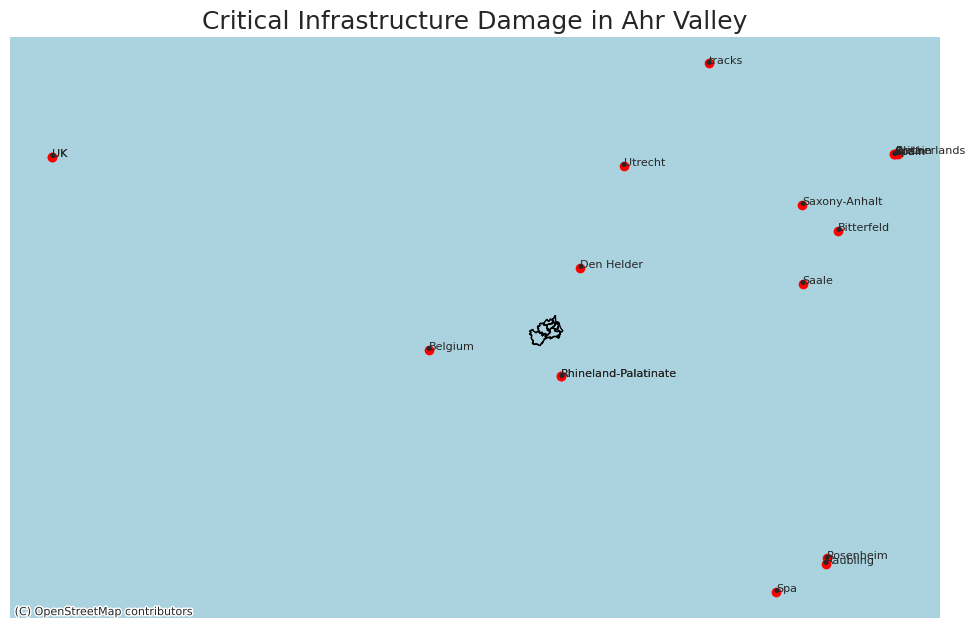

In [ ]:


# Example: load shapefile (replace gadm41_DEU_ your path)
gdf_regions = gpd.read_file("../../data/visualization/admin_borders/gadm41_DEU_3.shp") # ahrweiler, bad kissingen

# Filter to Ahr valley region (Ahrweiler district)
gdf_regions = gdf_regions[gdf_regions["NAME_2"].str.contains("Ahrweiler", na=False)]
# gdf_cities = gdf_regions[gdf_regions["NAME_3"].str.contains("Sinzig", na=False)] # example

# Spatial join: assign each point to a region
gdf_points = gdf_points.to_crs(gdf_regions.crs)

gdf_joined = gpd.sjoin(gdf_points, gdf_regions, how="left", predicate="within")

icon_map = {
    "energy": "⚡",
    "transport": "🚧",
    "water": "💧",
    "digital": "📡",
    "health": "🏥"
}

fig, ax = plt.subplots(figsize=(12, 12))

# --- Plot regions (polygons) ---
gdf_regions.boundary.plot(ax=ax, linewidth=1, color="black")

# --- Plot points ---
gdf_points.plot(ax=ax, color="red", markersize=30)

# --- Add city labels ---
for idx, row in gdf_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["location"],
        fontsize=8
    )

# --- Add infrastructure icons ---
for idx, row in gdf_points.iterrows():
    icon = icon_map.get(str(row["infrastructure_group"]).lower(), "•")

    ax.text(
        row.geometry.x,
        row.geometry.y,
        icon,
        fontsize=12,
        ha="center",
        va="center"
    )

# --- Add basemap ---
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

ax.set_axis_off()
plt.title("Critical Infrastructure Damage in Ahr Valley")

plt.show()

In [ ]:
## clustered MAP

import pandas as pd
import folium
from folium.plugins import MarkerCluster
from geopy.geocoders import Nominatim

df_plot_2 = df_plot.copy(deep=True)

geolocator = Nominatim(user_agent="ahr_cluster_map")

def geocode(loc):
    try:
        location = geolocator.geocode(f"{loc}, Ahrweiler, Germany")
        if location:
            return Point(location.longitude, location.latitude) if location else None
            #return pd.Series([location.latitude, location.longitude])
    except:
        return None
        # return pd.Series([None, None])

# df_plot_2[["lat", "lon"]] = df_plot_2["location"].apply(geocode)
df_plot_2["geometry"] = df_plot_2["location"].apply(geocode)
df_points_2 = df_plot_2.dropna(subset=["geometry"])

icon_map = {
    "energy": ("bolt", "orange"),
    "transport": ("road", "blue"),
    "water": ("tint", "cadetblue"),
    "digital": ("signal", "purple"),
    "health": ("plus", "red"),
}

m = folium.Map(location=[50.5, 7.0], zoom_start=10)
marker_cluster = MarkerCluster().add_to(m)

## ad clustered markers
for _, row in df_plot_2.iterrows():
    group = str(row["infrastructure_group"]).lower()
    icon_name, color = icon_map.get(group, ("info-sign", "gray"))

    folium.Marker(
        location=[row["lat"], row["lon"]],
        popup=f"{row['location']}<br>{row['infrastructure_group']}",
        icon=folium.Icon(icon=icon_name, prefix="fa", color=color)
    ).add_to(marker_cluster)
# save + open in browser
m.save("ahr_infrastructure_cluster_map.html")

In [ ]:
df_plot["location"]#.apply(geocode)
# df_plot[["lat", "lon"]] = df_plot["location"].apply(geocode)
# df_plot = df_plot.dropna(subset=["lat", "lon"])


##### Left overs - plotting

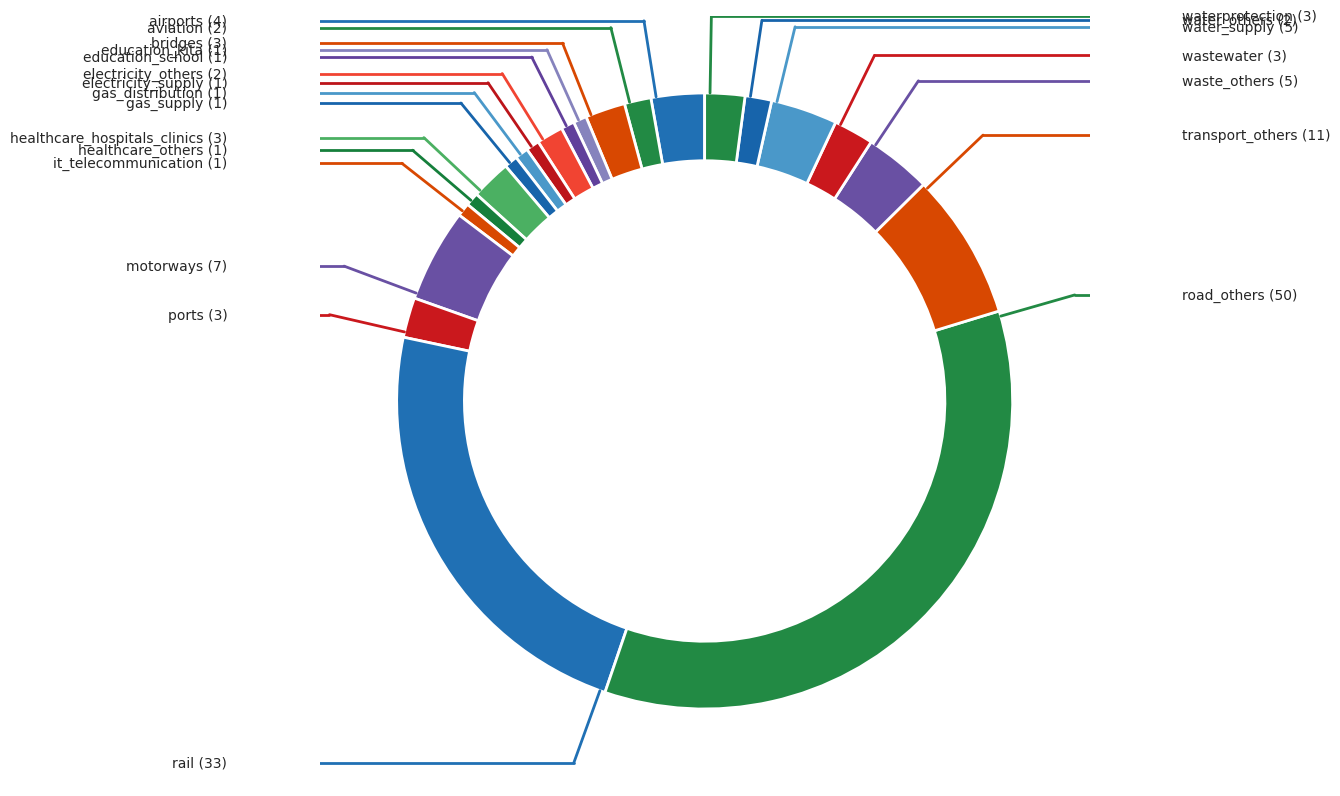

In [ ]:
# * histogram plot showing which are most common in the prediction set

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# --- Load your CSV ---
# Example CSV should have columns: category, value

# df_pred_plot = df_pred.groupby(["infrastructure_sector"])["infrastructure_group"].count().reset_index(name="infrastructure_group").sort_values(["infrastructure_group"], ascending=True)
# # df_pred[df_pred["infrastructure_group"].sort_values(ascending=False)]
# labels = df_pred_plot["infrastructure_group"].value_counts().index.tolist()  # get category labels in order of frequency
# sizes = df_pred_plot["infrastructure_group"].values
# groups = df_pred_plot["infrastructure_sector"]

df_plot = df_pred.copy()
# --- Aggregate data correctly ---
df_plot = (
    df_plot
    .groupby(["infrastructure_sector", "infrastructure_group"])
    .size()
    .reset_index(name="count")
)

# Sort by group then value (important for visual grouping)
df_plot = df_plot.sort_values(
    ["infrastructure_sector", "count"],
    ascending=[True, False]
)

labels = df_plot["infrastructure_group"]
sizes = df_plot["count"]
groups = df_plot["infrastructure_sector"]

# --- Seaborn style ---
sns.set_theme(style="white", context="talk")

# --- Grouped color palettes (soft infographic style) ---
unique_groups = groups.unique()
base_palettes = ["Blues", "Greens", "Oranges", "Purples", "Reds"]

group_palettes = {}
for i, group in enumerate(unique_groups):
    n = (groups == group).sum()
    # Use lighter range for infographic feel
    palette = sns.color_palette(base_palettes[i % len(base_palettes)], n + 2)[2:]
    group_palettes[group] = palette

# Assign colors in order
colors = []
counters = {g: 0 for g in unique_groups}

for g in groups:
    colors.append(group_palettes[g][counters[g]])
    counters[g] += 1

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 10))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    wedgeprops=dict(
        width=0.22,           # thinner ring (closer to infographic)
        edgecolor="white",    # creates separation between segments
        linewidth=2
    )
)

# --- Leader lines at END of each segment ---
for i, wedge in enumerate(wedges):
    # Use END of wedge instead of center
    angle = wedge.theta2 -1
    rad = np.deg2rad(angle)

    x, y = np.cos(rad), np.sin(rad)

    # Start exactly at outer edge
    r_outer = 1.0
    r_mid = 1.25

    start = (x * r_outer, y * r_outer)
    mid = (x * r_mid, y * r_mid)

    # Push labels further out for clarity
    end_x = 1.55 if x > 0 else -1.55
    end_y = mid[1]

    align = "left" if x > 0 else "right"

    # Draw leader lines (now anchored at segment END)
    ax.plot([start[0], mid[0]], [start[1], mid[1]],
            color=colors[i], lw=2)
    ax.plot([mid[0], end_x], [mid[1], end_y],
            color=colors[i], lw=2)

    # Label
    ax.text(
        end_x,
        end_y,
        f"{labels.iloc[i]} ({sizes.iloc[i]})",
        ha=align,
        va="center",
        fontsize=10
    )

In [ ]:
# * histogram plot showing which are most common in the prediction set

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# --- Load your CSV ---
# Example CSV should have columns: category, value

df_pred_plot = df_pred.groupby(["infrastructure_sector"])["infrastructure_group"].count().reset_index(name="infrastructure_group").sort_values(["infrastructure_group"], ascending=True)
# df_pred[df_pred["infrastructure_group"].sort_values(ascending=False)]
labels = df_pred_plot["infrastructure_group"].value_counts().index.tolist()  # get category labels in order of frequency
sizes = df_pred_plot["infrastructure_group"].values
groups = df_pred_plot["infrastructure_sector"]


# --- Seaborn styling ---
sns.set_theme(style="white")

# --- Create color mapping per group ---
unique_groups = groups.unique()
group_palettes = {}

# Assign a base palette per group
base_palettes = ["Blues", "Greens", "Reds", "Purples", "Oranges"]

for i, group in enumerate(unique_groups):
    count = sum(groups == group)
    palette = sns.color_palette(base_palettes[i % len(base_palettes)], count)
    group_palettes[group] = palette

# Flatten colors in correct order
colors = []
group_counters = {g: 0 for g in unique_groups}

for g in groups:
    colors.append(group_palettes[g][group_counters[g]])
    group_counters[g] += 1

# --- Create donut chart ---
fig, ax = plt.subplots(figsize=(8, 8))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    wedgeprops=dict(width=0.25)  # thin ring
)

# --- Leader lines ---
for i, wedge in enumerate(wedges):
    angle = (wedge.theta2 + wedge.theta1) / 2
    angle_rad = np.deg2rad(angle)

    x = np.cos(angle_rad)
    y = np.sin(angle_rad)

    start_x, start_y = x * 1.0, y * 1.0
    mid_x, mid_y = x * 1.2, y * 1.2
    end_x = 1.4 if x > 0 else -1.4
    end_y = mid_y

    align = "left" if x > 0 else "right"

    # Colored leader lines
    ax.plot([start_x, mid_x], [start_y, mid_y], color=colors[i], lw=1.5)
    ax.plot([mid_x, end_x], [mid_y, end_y], color=colors[i], lw=1.5)

    # Label includes group (optional)
    ax.text(
        end_x,
        end_y,
        "sss", #f"{labels[i]} ({sizes[i]})",
        ha=align,
        va="center",
        fontsize=10
    )

# --- Final styling ---
ax.set(aspect="equal")
plt.title("Donut Chart with Grouped Color Shades", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:

# --- Seaborn styling ---
sns.set_theme(style="white")

# --- Create color mapping per group ---
unique_groups = groups.unique()
group_palettes = {}

# Assign a base palette per group
base_palettes = ["Blues", "Greens", "Reds", "Purples", "Oranges"]

for i, group in enumerate(unique_groups):
    count = sum(groups == group)
    palette = sns.color_palette(base_palettes[i % len(base_palettes)], count)
    group_palettes[group] = palette

# Flatten colors in correct order
colors = []
group_counters = {g: 0 for g in unique_groups}

for g in groups:
    colors.append(group_palettes[g][group_counters[g]])
    group_counters[g] += 1

# --- Create donut chart ---
fig, ax = plt.subplots(figsize=(8, 8))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    wedgeprops=dict(width=0.25)  # thin ring
)

# --- Leader lines ---
for i, wedge in enumerate(wedges):
    angle = (wedge.theta2 + wedge.theta1) / 2
    angle_rad = np.deg2rad(angle)

    x = np.cos(angle_rad)
    y = np.sin(angle_rad)

    start_x, start_y = x * 1.0, y * 1.0
    mid_x, mid_y = x * 1.2, y * 1.2
    end_x = 1.4 if x > 0 else -1.4
    end_y = mid_y

    align = "left" if x > 0 else "right"

    # Colored leader lines
    ax.plot([start_x, mid_x], [start_y, mid_y], color=colors[i], lw=1.5)
    ax.plot([mid_x, end_x], [mid_y, end_y], color=colors[i], lw=1.5)

    # Label includes group (optional)
    ax.text(
        end_x,
        end_y,
        f"{labels[i]} ({sizes[i]})",
        ha=align,
        va="center",
        fontsize=10
    )

# --- Final styling ---
ax.set(aspect="equal")
plt.title("Donut Chart with Grouped Color Shades", fontsize=14)

plt.tight_layout()
plt.show()


In [ ]:

# # --- Seaborn styling ---
# sns.set_theme(style="white")
# colors = sns.color_palette("tab10", len(df_pred))

# # --- Create donut chart ---
# fig, ax = plt.subplots(figsize=(8, 8))

# wedges, _ = ax.pie(
#     sizes,
#     colors=colors,
#     startangle=90,
#     wedgeprops=dict(width=0.25)  # thinner ring
# )

# # --- Add colored leader lines and labels ---
# for i, wedge in enumerate(wedges):
#     angle = (wedge.theta2 + wedge.theta1) / 2
#     angle_rad = np.deg2rad(angle)

#     # Outer edge of donut (exact end of subsection)
#     x = np.cos(angle_rad)
#     y = np.sin(angle_rad)

#     # Start at outer edge of donut
#     start_x = x * 1.0
#     start_y = y * 1.0

#     # Extend outward
#     mid_x = x * 1.2
#     mid_y = y * 1.2

#     # Horizontal extension for label alignment
#     end_x = 1.4 if x > 0 else -1.4
#     end_y = mid_y

#     align = "left" if x > 0 else "right"

#     # Draw two-segment leader line (radial + horizontal)
#     ax.plot([start_x, mid_x], [start_y, mid_y], color=colors[i], lw=1.5)
#     ax.plot([mid_x, end_x], [mid_y, end_y], color=colors[i], lw=1.5)

#     # Add label
#     ax.text(
#         end_x,
#         end_y,
#         f"{labels[i]} ({sizes[i]})",
#         ha=align,
#         va="center",
#         fontsize=10
#     )

# # --- Final styling ---
# ax.set(aspect="equal")
# plt.title("Improved Donut Chart with Colored Leader Lines", fontsize=14)

# plt.tight_layout()
# plt.show()

### Valid DS / PRed DS load

In [122]:
# VALID_DATA_FILENAME = "table_ci_impacts_sm_casc_hpc.csv"
# PATH_VALID_DATA = s.PATH_VALID_DATA


# df_valid_org = pd.read_csv((PATH_VALID_DATA / VALID_DATA_FILENAME), )


# print(len(df_valid_org))
# ## pre-process: 
# # remove undone entries
# df_valid_org = df_valid_org[~df_valid_org.astype(str).apply(lambda x: x.str.contains("xx")).any(axis=1)]
# # remove further location info (e.g. that entry is a town, Landkreis, Bavaria etc.)
# df_valid_org = df_valid_org.dropna(subset=["publication_id"], how="all") # drop rows where citation info is missing
# print(len(df_valid_org))
# # print(df_valid_org.publication_id.unique())


# print("Use only citations which are in both")

# df_valid = df_valid_org[df_valid_org["publication_id"].isin(df_pred.citation_id.unique())]
# # df_valid_org[df_valid_org["publication_id"].isin(citation_list)]
# print("Valid citations:")
# print(set(sorted(df_valid.publication_id)))

# df = df_valid


In [123]:
import pandas as pd

# df_pred = pd.DataFrame()
# for i, file in enumerate(glob.glob(os.path.join("../interim_results_debug", f'llm_geollm_chain_{step}_*.csv'))):
#     try:
#         df_pred = pd.concat([df_pred, pd.read_csv(file)], ignore_index=True)
#     except:
#         print("Not added: ", i, file)
#         pass

# # df_pred.citation_id.unique()


print("Use only citations which are in both")

# Keep only entries which are also in preidction set
# df_pred = df_pred[df_pred["citation_id"].isin(df_valid.publication_id.unique())]
print(f"Predicted citations [{len(set(sorted(df_pred.citation_id)))} docs]:")
print(set(sorted(df_pred.citation_id)))


df_plot = df_pred


Use only citations which are in both
Predicted citations [17 docs]:
{'Ferlita 2023', 'Khazai 2013', 'Wildhagen 2013', 'ABC 2024', 'Koks 2022', 'Skoulding 2023', 'Wilson 2024', 'Containerlift 2024', 'AFP 2022', 'Karakatsani 2023', 'European Investment Bank 2025', 'Rozendaal 2021', 'Euronews 2024', 'Brown 2010', "Lloyd's List 2024", 'EFE 2024', 'Fink 2004'}


In [124]:
# handle concatenated entries
print(df_plot.economic_impact_origin.value_counts())
df_plot = pp.split_text_into_multiple_rows(df_plot, "economic_impact_origin", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "economic_impact_type", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "societal_impact_origin", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "societal_impact_type", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "secondary_infrastructure_asset", ", ")
print(df_plot.economic_impact_origin.value_counts())
## remove duplicates 
print(f"\nDropping {df_plot.duplicated().sum()} duplicates in postprocessed prediction data")
df_plot = df_plot.drop_duplicates()
print(f"Dropping { df_plot.shape[0] - df_plot[df_plot.duplicated() == False].shape[0]} duplicates in pred data")
df_plot = df_plot[df_plot.duplicated() == False]




economic_impact_origin
repair_recovery_cost                                                                                 16
downstream_economic_consequence                                                                      16
downstream_economic_consequence, downstream_economic_consequence, downstream_economic_consequence     3
Name: count, dtype: int64
economic_impact_origin
downstream_economic_consequence    29
repair_recovery_cost               16
Name: count, dtype: int64

Dropping 0 duplicates in postprocessed prediction data
Dropping 0 duplicates in pred data


In [125]:

# df = df_pred
# df = pp.split_ci_entities(df, columns=["infrastructure_type"])
# df["secondary_infrastructure_group"] = None
# # redo CI group creation as "split_ci_entities()" just splitted concatinated entries ("road and rail network")
# # # if not "infrastructure_group" in df.columns or df["infrastructure_group"].isna().any():
# df = pp.group_ci_types(df, "infrastructure_type", "infrastructure_group", ci_patterns)
# df = pp.group_ci_types(df, "secondary_infrastructure_asset", "secondary_infrastructure_group", ci_patterns)

# # keep only records which are actually about CI (e.g., not theatre, stadion ..)
# df.dropna(subset=["infrastructure_group"], inplace=True)

In [126]:

# df_plot = df.copy(deep=True)

## Prep - create sector and subsector ("group") columns with nice labels 
# print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group"].str.split(" - ").str[0]
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].str.split(" - ").str[1]


# # group into sectors
# df_plot["infrastructure_group4sector"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # # print(df_plot["secondary_infrastructure_group"].unique())
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group4sector"].str.split(" - ").str[0]

# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # # print(df_plot["secondary_infrastructure_group"].unique())
# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_sector"].str.split(" - ").str[0]





In [127]:
# df_plot[df_plot['secondary_infrastructure_asset'] == df_plot["infrastructure_type"]]
#except:
  #  df_plot['secondary_infrastructure_asset'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_asset'] == row["ci1_type"] else row['secondary_infrastructure_asset'], axis=1)
 #   
#df_plot['secondary_infrastructure_group'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_group'] == row["infrastructure_group"] else row['secondary_infrastructure_group'], axis=1)


In [128]:

## remove secondary_infrastructure_asset and secondary_infrastructure_asset-group entry when it is identical to  infrastructure_group
try:
    df_plot['secondary_infrastructure_asset'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_asset'] == row["infrastructure_type"] else row['secondary_infrastructure_asset'], axis=1)
except:
    df_plot['secondary_infrastructure_asset'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_asset'] == row["ci1_type"] else row['secondary_infrastructure_asset'], axis=1)
    
df_plot['secondary_infrastructure_group'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_group'] == row["infrastructure_group"] else row['secondary_infrastructure_group'], axis=1)


## remove economic_impact_origin entry when it economic_impact_type is NAN or None
print(df_plot.economic_impact_origin.value_counts())
df_plot['economic_impact_origin'] = df_plot.apply(lambda row: None if  (row["economic_impact_type"] in ["None", None, "none", np.nan, "NAN"] ) else row['economic_impact_origin'], axis=1)
print(df_plot.economic_impact_origin.value_counts())

print(df_plot.societal_impact_origin.value_counts())
df_plot['societal_impact_origin'] = df_plot.apply(lambda row: None if  (row["societal_impact_type"] in ["None", None, "none", np.nan, "NAN"] ) else row['societal_impact_origin'], axis=1)
print(df_plot.societal_impact_origin.value_counts())


df_plot[
    [
    # "infrastructure_type", "location", "damage", 
    "infrastructure_group", #"infrastructure_sector", 
    "economic_impact_type", "societal_impact_type", "secondary_infrastructure_asset", "secondary_infrastructure_group", "secondary_infrastructure_sector"]
][100:]

economic_impact_origin
downstream_economic_consequence    29
repair_recovery_cost               16
Name: count, dtype: int64
economic_impact_origin
downstream_economic_consequence    29
repair_recovery_cost               16
Name: count, dtype: int64
societal_impact_origin
disruption_of_mobility                         24
loss_of_critical_service_or_inaccessibility    16
other_affected_population                      13
evacuation_or_displacement                      6
Name: count, dtype: int64
societal_impact_origin
disruption_of_mobility                         17
loss_of_critical_service_or_inaccessibility    14
other_affected_population                      13
evacuation_or_displacement                      6
Name: count, dtype: int64


,infrastructure_group,economic_impact_type,societal_impact_type,secondary_infrastructure_asset,secondary_infrastructure_group,secondary_infrastructure_sector
100,rail,NaN,NaN,NaN,NaN,NaN
101,rail,NaN,NaN,NaN,NaN,NaN
102,electricity_general,NaN,people experienced power outages,NaN,NaN,NaN
103,electricity_general,NaN,NaN,power outages,electricity_supply,Energy
104,gas_distribution,NaN,NaN,Gas supply,gas_supply,Energy
...,...,...,...,...,...,...
257,aviation,NaN,disrupted mobility,NaN,NaN,NaN
258,airports,NaN,NaN,NaN,NaN,NaN
259,rail,Flood damage,NaN,NaN,NaN,NaN
260,rail,repair cost,inconvenience for passengers,NaN,NaN,NaN


In [129]:
# df_plot.societal_impact_type.value_counts()


df_plot[
    [
    # "infrastructure_type", "location", "damage", 
    "infrastructure_group", #"infrastructure_sector", 
    "economic_impact_type", "societal_impact_type", "secondary_infrastructure_asset", "secondary_infrastructure_group", "secondary_infrastructure_sector"]
][0:25]

df_plot[~df_plot["secondary_infrastructure_group"].isna()] #and ~df_plot["infrastructure_type"].isna()]#[["economic_impact_origin", "economic_impact_type", "economic_impact_amount", "chunk_text"]]

,is_infrastructure_case,infrastructure_type,infrastructure_amount,location,damage,economic_impact_type,economic_impact_origin,economic_impact_amount,economic_impact_unit,societal_impact_origin,...,location_orig,judge_verdict,judge_adapted_fields,judge_reason,judge_evidence,judge_evidence_in_text,judge_adaptation_in_text,infrastructure_sector,secondary_infrastructure_group,secondary_infrastructure_sector
0,True,Valencia Airport,NaN,Valencia Airport,disruption,NaN,NaN,NaN,NaN,disruption_of_mobility,...,"Valencia Airport, eastern Spain",adapted,"{""damage"": {""old"": ""service_loss"", ""new"": ""disruption""}, ""economic_impact_origin"": {""old"": ""downstream_economic_consequence"", ""new"": null}, ""economic_impact_type"": {""old"": ""flight cancellations and diversions"", ""new"": null}, ""societal_impact_type"": {""old"": ""passengers unable to travel"", ""new"": ""flights diverted and cancellations""}}","Damage for transportation infrastructure (airport) should be 'disruption' (halted/operational status). Flight cancellations/diversions are societal impacts (disruption of mobility), not economic impacts, as no monetary value is mentioned. 'flights' is not a secondary infrastructure asset but the service being disrupted.","Flights were briefly halted at Valencia Airport in eastern Spain yesterday after lightning and heavy flooding struck the runway following hours of torrential rain, airport officials said. ... 'Valencia airport is now operational. In the end, 10 flights were diverted to other airports and there were 28 cancellations,' it said on Twitter.",False,False,Transportation,aviation,Transportation
1,True,Valencia airport,NaN,Valencia airport,disruption,NaN,NaN,NaN,NaN,NaN,...,"Valencia, Spain",adapted,"{""location"": {""old"": ""Valencia"", ""new"": ""Valencia airport""}, ""damage"": {""old"": ""service_loss"", ""new"": ""disruption""}, ""societal_impact_type"": {""old"": ""affected people unable to travel due to runway closure"", ""new"": null}}","Location should be the asset name for transportation; damage 'close the runway' is disruption, not service_loss; societal impact is not explicitly stated; the road is not a consequence of the airport damage.","'Valencia airport has had to close the runway due to water accumulation, according to the airport's operations centre,' the emergency services tweeted.",True,False,Transportation,roads,Transportation
4,True,Valencia airport,NaN,Valencia airport,disruption,NaN,NaN,NaN,NaN,NaN,...,"Valencia, Spain",adapted,"{""location"": {""old"": ""Valencia"", ""new"": ""Valencia airport""}, ""damage"": {""old"": ""service_loss"", ""new"": ""disruption""}, ""societal_impact_type"": {""old"": ""affected people unable to travel due to runway closure"", ""new"": null}}",Duplicate of record 0; same corrections applied.,"'Valencia airport has had to close the runway due to water accumulation, according to the airport's operations centre,' the emergency services tweeted.",True,False,Transportation,roads,Transportation
19,True,village streets,NaN,eastern and southern Spain,inundation,NaN,NaN,NaN,NaN,other_affected_population,...,village streets in eastern and southern Spain,adapted,"{""location"": {""old"": ""village streets in eastern and southern Spain"", ""new"": ""eastern and southern Spain""}, ""societal_impact_origin"": {""old"": ""other_affected_population, other_affected_population, other_affected_population"", ""new"": ""other_affected_population""}, ""societal_impact_type"": {""old"": ""missing people, trapped people, missing truck driver"", ""new"": ""people reported missing""}, ""societal_impact_amount"": {""old"": ""several, several, one"", ""new"": ""Several""}, ""societal_impact_unit"": {""old"": ""people, people, driver"", ""new"": ""people""}}",Location should not include the asset type. Societal impacts were incorrectly aggregated from different locations/events into one record; only the missing people mentioned in the same sentence as village streets should be included. 

In [130]:

# df_plot['economic_impact_type'] = df_plot['economic_impact_type'].map({"NAN":False, None:False})
# df_plot.economic_impact_type = df_plot.economic_impact_type.astype(bool) # all str --> True
# df_plot['economic_impact_type'] = df_plot['economic_impact_type'].map({True:"Economic impacts"})
# # df_plot['economic_impacts'] = df_plot['economic_impacts'].map({np.nan:"No cascading impact"})

# df_plot['societal_impact_type'] = df_plot['societal_impact_type'].map({"NAN":False, None:False})
# df_plot.societal_impact_type = df_plot.societal_impact_type.astype(bool)
# df_plot['societal_impact_type'] = df_plot['societal_impact_type'].map({True:"Societal impacts"})

# df_plot['infrastructure_impacts_group'] = df_plot['infrastructure_impacts_group'].map({"NAN":False, None:False})

# df_plot['societal_impacts'] = df_plot['societal_impacts'].map({np.nan:"No cascading impact"})

df_plot[["economic_impact_type", "societal_impact_type", 'infrastructure_impacts_group']] = df_plot[["economic_impact_type", "societal_impact_type", 'secondary_infrastructure_group']].replace(np.nan, "No cascading impact")


print(df_plot.economic_impact_type.value_counts())
print(df_plot.societal_impact_type.value_counts())
print(df_plot.secondary_infrastructure_group.value_counts())

df_plot[
    [    # "infrastructure_type", "location", "damage", 
    "infrastructure_group", "infrastructure_sector", 
    "economic_impact_type", "societal_impact_type", "secondary_infrastructure_asset", "secondary_infrastructure_group",  "secondary_infrastructure_sector"]
][:20]


economic_impact_type
No cascading impact                                                 215
repair cost                                                          11
transportation disruption                                             4
supply-chain disruption                                               3
increased volume of waste equivalent to 30 years of collection        3
storage costs for 160 000 t at abandoned highway track                3
cleanup costs for waste deposits along river banks                    3
production loss                                                       2
service disruption                                                    2
loss of electricity supply                                            2
reconstruction cost                                                   1
energy shortage                                                       1
power outage                                                          1
price increase                             

,infrastructure_group,infrastructure_sector,economic_impact_type,societal_impact_type,secondary_infrastructure_asset,secondary_infrastructure_group,secondary_infrastructure_sector
0,airports,Transportation,No cascading impact,flights diverted and cancellations,flights,aviation,Transportation
1,airports,Transportation,No cascading impact,No cascading impact,a nearby road,roads,Transportation
2,airports,Transportation,No cascading impact,No cascading impact,NaN,NaN,NaN
3,healthcare_clinics,Health,No cascading impact,No cascading impact,NaN,NaN,NaN
4,airports,Transportation,No cascading impact,No cascading impact,a nearby road,roads,Transportation
5,roads,Transportation,No cascading impact,No cascading impact,NaN,NaN,NaN
6,electricity_supply,Energy,No cascading impact,No cascading impact,NaN,NaN,NaN
7,electricity_supply,Energy,reconstruction cost,No cascading impact,NaN,NaN,NaN
8,electricity_supply,Energy,No cascading impact,No cascading impact,NaN,NaN,NaN
9,electricity_supply,Energy,No cascading impact,No cascading impact,NaN,NaN,NaN


In [135]:
# df_plot.secondary_infrastructure_group.value_counts()

## Sankey plot - CI cascades

In [163]:
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt


# ============================================================
# Base palettes
# ============================================================

base_palettes = {

    "Transportation": "bone_r",
    "Energy": "Oranges",
    "Water": "Blues",
    "Structural Protection Measures": "BrBG_r",
    "Waste": "copper_r",
    "Education": "PuRd",
    "Health": "PuRd",
    "Other": "Greys_r",
    "IT / Communication": "Purples_r",
}


# ============================================================
# Helper: convert matplotlib colour to Plotly RGBA
# ============================================================

def cmap_to_rgba(
    cmap_name,
    position=0.60,
    alpha=1.0
):
    cmap = plt.colormaps[cmap_name]
    rgba = cmap(position)

    return (
        f"rgba("
        f"{int(rgba[0] * 255)},"
        f"{int(rgba[1] * 255)},"
        f"{int(rgba[2] * 255)},"
        f"{alpha}"
        f")"
    )


# ============================================================
# Fixed colour per sector
# ============================================================

sector_colors = {
    sector: cmap_to_rgba(
        palette,
        position=0.60,
        alpha=1.0
    )
    for sector, palette in base_palettes.items()
}


# ============================================================
# Group -> sector mapping
# ============================================================

def create_group_sector_mapping(
    df,
    group_col,
    sector_col
):

    # If the columns don't exist, return an empty mapping
    if group_col not in df.columns or sector_col not in df.columns:
        return {}

    temp = (
        df[[group_col, sector_col]]
        .dropna(subset=[group_col, sector_col])
        .copy()
    )

    temp[group_col] = (
        temp[group_col]
        .astype(str)
        .str.strip()
    )

    temp[sector_col] = (
        temp[sector_col]
        .astype(str)
        .str.strip()
    )

    temp = temp[
        (temp[group_col] != "") &
        (temp[sector_col] != "")
    ]

    mapping = (
        temp
        .drop_duplicates(subset=[group_col])
        .set_index(group_col)[sector_col]
        .to_dict()
    )

    return mapping


# ============================================================
# Sankey function
# ============================================================

NO_CASCADE = "No cascading impact"

# values treated as "no impact" in the impact columns
EMPTY_VALUES = {"", "nan", "none", "null", "n/a"}

# label of the "No cascading impact" node per impact group
NO_CASCADE_LABELS = {
    "Economic": "No cascading impact (economic)",
    "Societal": "No cascading impact (societal)",
    "Infrastructure": "No cascading impact (CI)",
}

# colour of the "No cascading impact" node per impact group
NO_CASCADE_COLORS = {
    "Economic": "rgba(31, 119, 180, 1)",     # blue, as the economic impacts
    "Societal": "rgba(231, 84, 128, 1)",     # pink, as the societal impacts
    "Infrastructure": "rgba(150,150,150,1)", # grey
}

def create_impact_sankey(
    df: pd.DataFrame,
    asset_col: str = "infrastructure_group",
    impact_cols: dict | None = None,
    link_alpha: float = 0.30,
):

    df = df.copy()

    # ========================================================
    # Identify impact columns
    # ========================================================

    if impact_cols is None:

        if "secondary_infrastructure_group" in df.columns:
            infrastructure_col = "secondary_infrastructure_group"

        elif "secondary_infrastructure_asset" in df.columns:
            infrastructure_col = "secondary_infrastructure_asset"

        else:
            raise ValueError(
                "Could not find 'secondary_infrastructure_group' "
                "or 'secondary_infrastructure_asset'."
            )

        impact_cols = {
            # "Economic": "economic_impact_type",
            "Economic": "economic_impact_origin",
            # "Societal": "societal_impact_type",
            "Societal": "societal_impact_origin",
            "Infrastructure": infrastructure_col,
        }

    # ========================================================
    # Group -> sector mappings
    # ========================================================

    source_group_sector = create_group_sector_mapping(
        df,
        "infrastructure_group",
        "infrastructure_sector"
    )

    target_group_sector = create_group_sector_mapping(
        df,
        "secondary_infrastructure_group",
        "secondary_infrastructure_sector"
    )

    # ========================================================
    # Create source-target relationships
    # ========================================================

    links = []

    for _, row in df.iterrows():

        asset = row.get(asset_col)

        if pd.isna(asset):
            continue

        asset = str(asset).strip()

        if not asset:
            continue

        # ----------------------------------------------------
        # Process the three impact columns separately:
        # NaN / None / empty / "No cascading impact" of a group
        # -> ONE "No cascading impact" node of THIS group
        # ----------------------------------------------------

        for impact_type, col in impact_cols.items():

            value = row.get(col)

            if pd.isna(value) or str(value).strip().lower() in EMPTY_VALUES:
                impacts = []
            else:
                # Split semicolon-separated impacts
                impacts = [
                    x.strip()
                    for x in str(value).split(";")
                    if x.strip() and x.strip().lower() not in EMPTY_VALUES
                ]

            # Ignore "No cascading impact" placeholders, keep only real impacts
            impacts = [
                x for x in impacts
                if x.lower() != NO_CASCADE.lower()
            ]

            if not impacts:
                impacts = [NO_CASCADE]

            for impact in impacts:

                links.append({
                    "source": asset,
                    "target": impact,
                    "target_type": impact_type,
                    "value": 1,
                })

    links = pd.DataFrame(links)

    if links.empty:
        raise ValueError(
            "No source-target relationships were found."
        )

    # ========================================================
    # Aggregate identical source-target relationships
    # ========================================================

    links = (
        links
        .groupby(
            ["source", "target", "target_type"],
            as_index=False
        )["value"]
        .sum()
    )


    # ========================================================
    # ORDER SOURCE NODES BY SECTOR AND SIZE
    # ========================================================

    # Size of each infrastructure group
    # = total number of source -> target links
    source_sizes = (
        links
        .groupby("source")["value"]
        .sum()
        .reset_index(name="size")
    )

    # Add infrastructure sector
    source_sizes["sector"] = (
        source_sizes["source"]
        .map(source_group_sector)
        .fillna("Other")
    )

    # --------------------------------------------------------
    # Order sectors by their total size
    # --------------------------------------------------------

    sector_sizes = (
        source_sizes
        .groupby("sector")["size"]
        .sum()
        .sort_values(ascending=False)
    )

    ordered_sectors = sector_sizes.index.tolist()

    # --------------------------------------------------------
    # Order infrastructure groups within each sector by size
    # --------------------------------------------------------

    ordered_sources = []

    for sector in ordered_sectors:

        sector_sources = (
            source_sizes[
                source_sizes["sector"] == sector
            ]
            .sort_values(
                "size",
                ascending=False
            )
        )

        ordered_sources.extend(
            sector_sources["source"].tolist()
        )

    # --------------------------------------------------------
    # Create source node IDs in the desired order
    # --------------------------------------------------------

    source_nodes = [
        f"asset::{x}"
        for x in ordered_sources
    ]

    # ========================================================
    # Create target nodes
    # ========================================================

    # Order: grouped by impact type (economic, societal, cascaded CI),
    # the group's "No cascading impact" node at the end of its block
    type_order = list(impact_cols)

    target_nodes = sorted(
        {f"{row.target_type}::{row.target}" for row in links.itertuples()},
        key=lambda node: (
            type_order.index(node.split("::", 1)[0]),
            node.split("::", 1)[1] == NO_CASCADE,
            node,
        ),
    )

    # ========================================================
    # All nodes
    # ========================================================

    all_node_ids = source_nodes + target_nodes

    # ========================================================
    # Node labels
    # ========================================================

    # Number of cases per node, shown as "<label> [<number of cases>]"
    # left:  number of cases (rows) of the infrastructure group
    # right: number of cases linked to the impact
    source_case_counts = (
        df[asset_col]
        .dropna()
        .astype(str)
        .str.strip()
        .loc[lambda x: x != ""]
        .value_counts()
    )

    target_case_counts = (
        links
        .assign(node=links["target_type"] + "::" + links["target"])
        .groupby("node")["value"]
        .sum()
    )

    node_labels = []

    for node in all_node_ids:

        if node.startswith("asset::"):

            label = node.replace("asset::", "")

            n_cases = source_case_counts.get(label, 0)

        else:

            target_type, label = node.split("::", 1)

            n_cases = target_case_counts.get(node, 0)

            if label == NO_CASCADE:
                label = NO_CASCADE_LABELS.get(target_type, f"{NO_CASCADE} ({target_type})")

        node_labels.append(f"{label} [{n_cases}]")

    # ========================================================
    # Node sectors and colours
    # ========================================================

    node_sectors = []
    node_colors = []

    for node in all_node_ids:

        # ----------------------------------------------------
        # SOURCE infrastructure node
        # ----------------------------------------------------

        if node.startswith("asset::"):

            group = node.replace("asset::", "")

            sector = source_group_sector.get(
                group,
                "Other"
            )

            color = sector_colors.get(
                sector,
                "rgba(150,150,150,1)"
            )

        # ----------------------------------------------------
        # TARGET node
        # ----------------------------------------------------

        else:

            target_type, group = node.split("::", 1)

            # "No cascading impact" of one of the three groups
            if group == NO_CASCADE:

                sector = f"{NO_CASCADE} ({target_type})"

                color = NO_CASCADE_COLORS.get(target_type, "rgba(150,150,150,1)")

            elif target_type == "Infrastructure":

                sector = target_group_sector.get(
                    group,
                    "Other"
                )

                color = sector_colors.get(
                    sector,
                    "rgba(150,150,150,1)"
                )

            elif target_type == "Economic":

                sector = "Economic"
                color = "rgba(31, 119, 180, 1)"   # blue
                # color = "rgba(220, 0, 0, 1)"    red

            elif target_type == "Societal":

                sector = "Societal"
                # color = "rgba(220, 0, 0, 1)" # red
                color = "rgba(231, 84, 128, 1)"   # pink

            else:

                sector = "Other"

                color = "rgba(150,150,150,1)"

        node_sectors.append(sector)
        node_colors.append(color)

    # ========================================================
    # Node -> Sankey index
    # ========================================================

    node_id_to_index = {
        node_id: i
        for i, node_id in enumerate(all_node_ids)
    }


    # ========================================================
    # EXPLICIT NODE POSITIONS
    # ========================================================

    node_x = []
    node_y = []

    # --------------------------------------------------------
    # LEFT SIDE
    # --------------------------------------------------------

    # Give each infrastructure sector its own block.
    # Larger sectors appear first.
    # Groups within each sector retain their size ordering.
    # --------------------------------------------------------

    n_sources = len(ordered_sources)

    # Small vertical gap between sectors
    sector_gap = 0.015

    # Total available vertical space
    available_height = 0.97

    # Number of sector gaps
    n_sector_gaps = max(len(ordered_sectors) - 1, 0)

    # Space remaining for nodes
    node_area = available_height - (
        n_sector_gaps * sector_gap
    )

    # Total source size
    total_source_size = source_sizes["size"].sum()

    source_y_positions = {}

    current_y = 0.01

    for sector in ordered_sectors:

        sector_data = (
            source_sizes[
                source_sizes["sector"] == sector
            ]
            .sort_values(
                "size",
                ascending=False
            )
        )

        sector_total = sector_data["size"].sum()

        # Vertical space proportional to sector size
        sector_height = (
            sector_total / total_source_size
        ) * node_area

        n_groups = len(sector_data)

        if n_groups == 1:

            spacing = sector_height / 2

        else:

            spacing = sector_height / n_groups

        for i, source in enumerate(
            sector_data["source"]
        ):

            source_y_positions[source] = (
                current_y
                + (i + 0.5) * spacing
            )

        current_y += sector_height
        current_y += sector_gap


    # Add source coordinates
    for source in ordered_sources:

        node_x.append(0.01)

        node_y.append(
            source_y_positions[source]
        )


    # --------------------------------------------------------
    # RIGHT SIDE
    # --------------------------------------------------------

    # Keep the existing target order, but explicitly position
    # the targets so that arrangement="fixed" can be used.
    # --------------------------------------------------------

    target_y_positions = {}

    n_targets = len(target_nodes)

    if n_targets == 1:

        target_y_positions[target_nodes[0]] = 0.5

    else:

        target_spacing = (
            0.96 / n_targets
        )

        for i, target in enumerate(target_nodes):

            target_y_positions[target] = (
                0.01
                + (i + 0.5) * target_spacing
            )


    # Add target coordinates
    for target in target_nodes:

        node_x.append(0.99)

        node_y.append(
            target_y_positions[target]
        )

    # ========================================================
    # Create Sankey links
    # ========================================================

    sankey_source = []
    sankey_target = []
    sankey_value = []
    sankey_link_colors = []
    sankey_source_sectors = []

    for row in links.itertuples():

        # ----------------------------------------------------
        # Source
        # ----------------------------------------------------

        source_id = f"asset::{row.source}"

        # ----------------------------------------------------
        # Target
        # ----------------------------------------------------

        target_id = (
            f"{row.target_type}::{row.target}"
        )

        # ----------------------------------------------------
        # Source sector
        # ----------------------------------------------------

        source_sector = source_group_sector.get(
            row.source,
            "Other"
        )

        # ----------------------------------------------------
        # Link inherits SOURCE sector colour
        # ----------------------------------------------------

        if source_sector in base_palettes:

            link_color = cmap_to_rgba(
                base_palettes[source_sector],
                position=0.60,
                alpha=link_alpha
            )

        else:

            link_color = (
                f"rgba(150,150,150,{link_alpha})"
            )

        sankey_source.append(
            node_id_to_index[source_id]
        )

        sankey_target.append(
            node_id_to_index[target_id]
        )

        sankey_value.append(row.value)

        sankey_link_colors.append(
            link_color
        )

        sankey_source_sectors.append(
            source_sector
        )

    # ========================================================
    # Create Sankey
    # ========================================================

    fig = go.Figure(
        go.Sankey(

            arrangement="snap",

            node=dict(
                label=node_labels,
                color=node_colors,

                pad=20,
                thickness=20,

                x=node_x,
                y=node_y,

                customdata=node_sectors,

                hovertemplate=(
                    "<b>%{label}</b>"
                    "<br>Sector: %{customdata}"
                    "<extra></extra>"
                ),
            ),

            link=dict(
                source=sankey_source,
                target=sankey_target,
                value=sankey_value,

                color=sankey_link_colors,

                customdata=sankey_source_sectors,

                hovertemplate=(
                    "%{source.label}"
                    " → "
                    "%{target.label}"
                    "<br>Cases: %{value}"
                    "<br>Source sector: %{customdata}"
                    "<extra></extra>"
                ),
            ),
        )
    )

    fig.update_layout(
        title="Infrastructure Assets and Cascading Impacts",
        font=dict(
            size=18
        ),
        width=1000,
        height=1400,
    )

    return fig, links

In [164]:
# df_plot.citation_id.value_counts()

In [165]:
fig, sankey_links = create_impact_sankey(df_plot)
fig

In [60]:
tt = sankey_links[sankey_links["target"]!="Economic impacts"]
tt = tt[tt["target"]!="Societal impacts"]
tt[tt["target"]!="No cascading impact"]

,source,target,target_type,value
3,Aviation,Transportation (not further specified),Infrastructure,2
5,Bridges,Road network,Infrastructure,1
22,Highways / Motorways,Transportation (not further specified),Infrastructure,4
32,Rail network,Rail service,Infrastructure,1
39,Road network,Rail network,Infrastructure,2
40,Road network,Rail service,Infrastructure,1
42,Road network,Transportation (not further specified),Infrastructure,3
47,Shipping traffic,Transportation (not further specified),Infrastructure,6
48,Transportation (not further specified),Aviation,Infrastructure,4
51,Transportation (not further specified),Shipping traffic,Infrastructure,1


## reste sankey plot

In [158]:
# import pandas as pd
# import plotly.graph_objects as go
# import matplotlib.pyplot as plt


# # ============================================================
# # Base palettes
# # ============================================================

# base_palettes = {

#     "Transportation": "bone_r",
#     "Energy": "Oranges",
#     "Water": "Blues",
#     "Structural Protection Measures": "BrBG_r",
#     "Waste": "copper_r",
#     "Education": "PuRd",
#     "Health": "PuRd",
#     "Other": "Greys_r",
#     "IT / Communication": "Purples_r",
# }


# # ============================================================
# # Helper: convert matplotlib colour to Plotly RGBA
# # ============================================================

# def cmap_to_rgba(
#     cmap_name,
#     position=0.60,
#     alpha=1.0
# ):
#     cmap = plt.colormaps[cmap_name]
#     rgba = cmap(position)

#     return (
#         f"rgba("
#         f"{int(rgba[0] * 255)},"
#         f"{int(rgba[1] * 255)},"
#         f"{int(rgba[2] * 255)},"
#         f"{alpha}"
#         f")"
#     )


# # ============================================================
# # Fixed colour per sector
# # ============================================================

# sector_colors = {
#     sector: cmap_to_rgba(
#         palette,
#         position=0.60,
#         alpha=1.0
#     )
#     for sector, palette in base_palettes.items()
# }


# # ============================================================
# # Group -> sector mapping
# # ============================================================

# def create_group_sector_mapping(
#     df,
#     group_col,
#     sector_col
# ):

#     # If the columns don't exist, return an empty mapping
#     if group_col not in df.columns or sector_col not in df.columns:
#         return {}

#     temp = (
#         df[[group_col, sector_col]]
#         .dropna(subset=[group_col, sector_col])
#         .copy()
#     )

#     temp[group_col] = (
#         temp[group_col]
#         .astype(str)
#         .str.strip()
#     )

#     temp[sector_col] = (
#         temp[sector_col]
#         .astype(str)
#         .str.strip()
#     )

#     temp = temp[
#         (temp[group_col] != "") &
#         (temp[sector_col] != "")
#     ]

#     mapping = (
#         temp
#         .drop_duplicates(subset=[group_col])
#         .set_index(group_col)[sector_col]
#         .to_dict()
#     )

#     return mapping


# # ============================================================
# # Sankey function
# # ============================================================

# def create_impact_sankey(
#     df: pd.DataFrame,
#     asset_col: str = "infrastructure_group",
#     impact_cols: dict | None = None,
#     link_alpha: float = 0.30,
# ):

#     df = df.copy()

#     # ========================================================
#     # Identify impact columns
#     # ========================================================

#     if impact_cols is None:

#         if "secondary_infrastructure_group" in df.columns:
#             infrastructure_col = "secondary_infrastructure_group"

#         elif "secondary_infrastructure_asset" in df.columns:
#             infrastructure_col = "secondary_infrastructure_asset"

#         else:
#             raise ValueError(
#                 "Could not find 'secondary_infrastructure_group' "
#                 "or 'secondary_infrastructure_asset'."
#             )

#         impact_cols = {
#             # "Economic": "economic_impact_type",
#             "Economic": "economic_impact_origin",
#             # "Societal": "societal_impact_type",
#             "Societal": "societal_impact_origin",
#             "Infrastructure": infrastructure_col,
#         }

#     # ========================================================
#     # Group -> sector mappings
#     # ========================================================

#     source_group_sector = create_group_sector_mapping(
#         df,
#         "infrastructure_group",
#         "infrastructure_sector"
#     )

#     target_group_sector = create_group_sector_mapping(
#         df,
#         "secondary_infrastructure_group",
#         "secondary_infrastructure_sector"
#     )

#     # ========================================================
#     # Create source-target relationships
#     # ========================================================

#     links = []

#     for _, row in df.iterrows():

#         asset = row.get(asset_col)

#         if pd.isna(asset):
#             continue

#         asset = str(asset).strip()

#         if not asset:
#             continue

#         row_impacts = []

#         # ----------------------------------------------------
#         # Process the three impact columns
#         # ----------------------------------------------------

#         for impact_type, col in impact_cols.items():

#             value = row.get(col)

#             # Empty value
#             if pd.isna(value):
#                 continue

#             # Split semicolon-separated impacts
#             impacts = [
#                 x.strip()
#                 for x in str(value).split(";")
#                 if x.strip()
#             ]

#             for impact in impacts:
#                 row_impacts.append(
#                     (impact_type, impact)
#                 )

#         # ----------------------------------------------------
#         # Determine whether this row has actual impacts
#         # ----------------------------------------------------

#         actual_impacts = [
#             (impact_type, impact)
#             for impact_type, impact in row_impacts
#             if impact.lower() != "no cascading impact"
#         ]

#         explicit_no_cascade = any(
#             impact.lower() == "no cascading impact"
#             for _, impact in row_impacts
#         )

#         # ----------------------------------------------------
#         # Case 1:
#         # No actual impacts at all
#         #
#         # This includes:
#         #   - all NaN
#         #   - explicit "No cascading impact"
#         # ----------------------------------------------------

#         if not actual_impacts:

#             links.append({
#                 "source": asset,
#                 "target": "No cascading impact",
#                 "target_type": "NoCascade",
#                 "value": 1,
#             })

#         # ----------------------------------------------------
#         # Case 2:
#         # Actual impacts exist
#         #
#         # Ignore "No cascading impact" placeholders
#         # and only keep the real impacts.
#         # ----------------------------------------------------

#         else:

#             for impact_type, impact in actual_impacts:

#                 links.append({
#                     "source": asset,
#                     "target": impact,
#                     "target_type": impact_type,
#                     "value": 1,
#                 })

#     links = pd.DataFrame(links)

#     if links.empty:
#         raise ValueError(
#             "No source-target relationships were found."
#         )

#     # ========================================================
#     # Aggregate identical source-target relationships
#     # ========================================================

#     links = (
#         links
#         .groupby(
#             ["source", "target", "target_type"],
#             as_index=False
#         )["value"]
#         .sum()
#     )


#     # ========================================================
#     # ORDER SOURCE NODES BY SECTOR AND SIZE
#     # ========================================================

#     # Size of each infrastructure group
#     # = total number of source -> target links
#     source_sizes = (
#         links
#         .groupby("source")["value"]
#         .sum()
#         .reset_index(name="size")
#     )

#     # Add infrastructure sector
#     source_sizes["sector"] = (
#         source_sizes["source"]
#         .map(source_group_sector)
#         .fillna("Other")
#     )

#     # --------------------------------------------------------
#     # Order sectors by their total size
#     # --------------------------------------------------------

#     sector_sizes = (
#         source_sizes
#         .groupby("sector")["size"]
#         .sum()
#         .sort_values(ascending=False)
#     )

#     ordered_sectors = sector_sizes.index.tolist()

#     # --------------------------------------------------------
#     # Order infrastructure groups within each sector by size
#     # --------------------------------------------------------

#     ordered_sources = []

#     for sector in ordered_sectors:

#         sector_sources = (
#             source_sizes[
#                 source_sizes["sector"] == sector
#             ]
#             .sort_values(
#                 "size",
#                 ascending=False
#             )
#         )

#         ordered_sources.extend(
#             sector_sources["source"].tolist()
#         )

#     # --------------------------------------------------------
#     # Create source node IDs in the desired order
#     # --------------------------------------------------------

#     source_nodes = [
#         f"asset::{x}"
#         for x in ordered_sources
#     ]

#     # ========================================================
#     # Create target nodes
#     # ========================================================

#     target_nodes = []

#     for row in links.itertuples():

#         # IMPORTANT:
#         # NoCascade has ONE shared node
#         if row.target_type == "NoCascade":

#             target_id = "no_cascade::No cascading impact"

#         else:

#             target_id = (
#                 f"{row.target_type}::{row.target}"
#             )

#         if target_id not in target_nodes:
#             target_nodes.append(target_id)

#     # ========================================================
#     # All nodes
#     # ========================================================

#     all_node_ids = source_nodes + target_nodes

#     # ========================================================
#     # Node labels
#     # ========================================================

#     node_labels = []

#     for node in all_node_ids:

#         if node.startswith("asset::"):

#             label = node.replace("asset::", "")

#         elif node.startswith("no_cascade::"):

#             label = "No cascading impact"

#         else:

#             label = node.split("::", 1)[1]

#         node_labels.append(label)

#     # ========================================================
#     # Node sectors and colours
#     # ========================================================

#     node_sectors = []
#     node_colors = []

#     for node in all_node_ids:

#         # ----------------------------------------------------
#         # SOURCE infrastructure node
#         # ----------------------------------------------------

#         if node.startswith("asset::"):

#             group = node.replace("asset::", "")

#             sector = source_group_sector.get(
#                 group,
#                 "Other"
#             )

#             color = sector_colors.get(
#                 sector,
#                 "rgba(150,150,150,1)"
#             )

#         # ----------------------------------------------------
#         # No cascading impact
#         # ----------------------------------------------------

#         elif node.startswith("no_cascade::"):

#             sector = "No cascading impact"

#             color = "rgba(220, 0, 0, 1)"

#         # ----------------------------------------------------
#         # TARGET node
#         # ----------------------------------------------------

#         else:

#             target_type, group = node.split("::", 1)

#             if target_type == "Infrastructure":

#                 sector = target_group_sector.get(
#                     group,
#                     "Other"
#                 )

#                 color = sector_colors.get(
#                     sector,
#                     "rgba(150,150,150,1)"
#                 )

#             elif target_type == "Economic":

#                 sector = "Economic"

#                 color = "rgba(220, 0, 0, 1)"

#             elif target_type == "Societal":

#                 sector = "Societal"

#                 color = "rgba(220, 0, 0, 1)"

#             else:

#                 sector = "Other"

#                 color = "rgba(150,150,150,1)"

#         node_sectors.append(sector)
#         node_colors.append(color)

#     # ========================================================
#     # Node -> Sankey index
#     # ========================================================

#     node_id_to_index = {
#         node_id: i
#         for i, node_id in enumerate(all_node_ids)
#     }


#     # ========================================================
#     # EXPLICIT NODE POSITIONS
#     # ========================================================

#     node_x = []
#     node_y = []

#     # --------------------------------------------------------
#     # LEFT SIDE
#     # --------------------------------------------------------

#     # Give each infrastructure sector its own block.
#     # Larger sectors appear first.
#     # Groups within each sector retain their size ordering.
#     # --------------------------------------------------------

#     n_sources = len(ordered_sources)

#     # Small vertical gap between sectors
#     sector_gap = 0.015

#     # Total available vertical space
#     available_height = 0.97

#     # Number of sector gaps
#     n_sector_gaps = max(len(ordered_sectors) - 1, 0)

#     # Space remaining for nodes
#     node_area = available_height - (
#         n_sector_gaps * sector_gap
#     )

#     # Total source size
#     total_source_size = source_sizes["size"].sum()

#     source_y_positions = {}

#     current_y = 0.01

#     for sector in ordered_sectors:

#         sector_data = (
#             source_sizes[
#                 source_sizes["sector"] == sector
#             ]
#             .sort_values(
#                 "size",
#                 ascending=False
#             )
#         )

#         sector_total = sector_data["size"].sum()

#         # Vertical space proportional to sector size
#         sector_height = (
#             sector_total / total_source_size
#         ) * node_area

#         n_groups = len(sector_data)

#         if n_groups == 1:

#             spacing = sector_height / 2

#         else:

#             spacing = sector_height / n_groups

#         for i, source in enumerate(
#             sector_data["source"]
#         ):

#             source_y_positions[source] = (
#                 current_y
#                 + (i + 0.5) * spacing
#             )

#         current_y += sector_height
#         current_y += sector_gap


#     # Add source coordinates
#     for source in ordered_sources:

#         node_x.append(0.01)

#         node_y.append(
#             source_y_positions[source]
#         )


#     # --------------------------------------------------------
#     # RIGHT SIDE
#     # --------------------------------------------------------

#     # Keep the existing target order, but explicitly position
#     # the targets so that arrangement="fixed" can be used.
#     # --------------------------------------------------------

#     target_y_positions = {}

#     n_targets = len(target_nodes)

#     if n_targets == 1:

#         target_y_positions[target_nodes[0]] = 0.5

#     else:

#         target_spacing = (
#             0.96 / n_targets
#         )

#         for i, target in enumerate(target_nodes):

#             target_y_positions[target] = (
#                 0.01
#                 + (i + 0.5) * target_spacing
#             )


#     # Add target coordinates
#     for target in target_nodes:

#         node_x.append(0.99)

#         node_y.append(
#             target_y_positions[target]
#         )

#     # ========================================================
#     # Create Sankey links
#     # ========================================================

#     sankey_source = []
#     sankey_target = []
#     sankey_value = []
#     sankey_link_colors = []
#     sankey_source_sectors = []

#     for row in links.itertuples():

#         # ----------------------------------------------------
#         # Source
#         # ----------------------------------------------------

#         source_id = f"asset::{row.source}"

#         # ----------------------------------------------------
#         # Target
#         # ----------------------------------------------------

#         if row.target_type == "NoCascade":

#             target_id = (
#                 "no_cascade::No cascading impact"
#             )

#         else:

#             target_id = (
#                 f"{row.target_type}::{row.target}"
#             )

#         # ----------------------------------------------------
#         # Source sector
#         # ----------------------------------------------------

#         source_sector = source_group_sector.get(
#             row.source,
#             "Other"
#         )

#         # ----------------------------------------------------
#         # Link inherits SOURCE sector colour
#         # ----------------------------------------------------

#         if source_sector in base_palettes:

#             link_color = cmap_to_rgba(
#                 base_palettes[source_sector],
#                 position=0.60,
#                 alpha=link_alpha
#             )

#         else:

#             link_color = (
#                 f"rgba(150,150,150,{link_alpha})"
#             )

#         sankey_source.append(
#             node_id_to_index[source_id]
#         )

#         sankey_target.append(
#             node_id_to_index[target_id]
#         )

#         sankey_value.append(row.value)

#         sankey_link_colors.append(
#             link_color
#         )

#         sankey_source_sectors.append(
#             source_sector
#         )

#     # ========================================================
#     # Create Sankey
#     # ========================================================

#     fig = go.Figure(
#         go.Sankey(

#             arrangement="snap",

#             node=dict(
#                 label=node_labels,
#                 color=node_colors,

#                 pad=20,
#                 thickness=20,

#                 x=node_x,
#                 y=node_y,

#                 customdata=node_sectors,

#                 hovertemplate=(
#                     "<b>%{label}</b>"
#                     "<br>Sector: %{customdata}"
#                     "<extra></extra>"
#                 ),
#             ),

#             link=dict(
#                 source=sankey_source,
#                 target=sankey_target,
#                 value=sankey_value,

#                 color=sankey_link_colors,

#                 customdata=sankey_source_sectors,

#                 hovertemplate=(
#                     "%{source.label}"
#                     " → "
#                     "%{target.label}"
#                     "<br>Cases: %{value}"
#                     "<br>Source sector: %{customdata}"
#                     "<extra></extra>"
#                 ),
#             ),
#         )
#     )

#     fig.update_layout(
#         title="Infrastructure Assets and Cascading Impacts",
#         font=dict(
#             size=18
#         ),
#         width=1200,
#         height=1400,
#     )

#     return fig, links

In [159]:
# fig, sankey_links = create_impact_sankey(df_plot)
# fig